# Dự đoán xác suất thắng map VALORANT theo từng round bằng mạng GRU

**Câu hỏi:** sau khi round hiện tại kết thúc, từ các thông tin đã biết, xác suất đội A thắng cả map là bao nhiêu?

Một dòng CSV gốc **chưa phải** một mẫu huấn luyện. Phải ghép điểm cuối map, kinh tế từng round và đội hình; sau đó mới tạo chuỗi round để đưa vào mạng. Nhãn là kết quả cuối map, nhưng điểm cuối không được đưa vào đầu vào.

Notebook gồm các bước: đọc dữ liệu → xem từng cột → kiểm tra chất lượng → ghép hai đội → tạo chuỗi → chia tập → mã hóa → huấn luyện → đánh giá → lưu hình cho báo cáo.

Thí nghiệm dùng **VCT 2023–2024**: các loạt trận năm 2023 được chia thành huấn luyện và kiểm định; toàn bộ năm 2024 là tập kiểm tra. Đây không phải chia theo ngày trong năm 2023 vì ba CSV sử dụng không có ngày thi đấu. Mẫu của cùng một map/loạt trận không được rơi vào hai tập.

Chọn kernel Python Homebrew đã cài trong Visual Studio Code, rồi chạy từ trên xuống. Phần huấn luyện chạy cả ba mô hình đối chứng và hai mạng GRU, nên lâu hơn các ô đọc CSV. Notebook không cài thư viện, không tạo môi trường ảo và không thay đổi cấu hình Python. File gốc vẫn nằm ngoài Git; bảng kiểm tra, dự đoán và hình được lưu trong `outputs/notebook/` đã được Git bỏ qua. Toàn bộ hàm dùng để tạo dữ liệu, baseline và GRU đều nằm trong notebook này.

## Thiết lập thư viện và đường dẫn

`import` nạp công cụ. `Path` xử lý đường dẫn; `pandas` xử lý bảng; `numpy` xử lý mảng số; `torch` xây dựng mạng; `matplotlib` vẽ hình. Đường dẫn dữ liệu có thể đổi bằng biến môi trường `VALORANT_DATA_ROOT`, không phải sửa từng ô.

In [1]:
# sys cho biết Python đang chạy và hỗ trợ tìm các module cần dùng.
import sys

# os dùng để đọc biến môi trường, không cài hoặc sửa Python.
import os

# json dùng để lưu kết quả thực nghiệm dạng cấu trúc.
import json

# random dùng để cố định các phép ngẫu nhiên của Python.
import random

# dataclass giúp gom một số cấu hình và kết quả có tên rõ ràng.
from dataclasses import dataclass

# Path nối thư mục bằng toán tử / và xử lý đường dẫn có khoảng trắng.
from pathlib import Path

# NumPy xử lý vector và ma trận số.
import numpy as np

# pandas xử lý các bảng CSV.
import pandas as pd

# pyplot tạo biểu đồ.
import matplotlib.pyplot as plt

# Hai lớp này vẽ mũi tên và khung trong sơ đồ xử lý dữ liệu.
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

# torch xử lý tensor và huấn luyện mạng học sâu.
import torch

# nn cung cấp các lớp mạng và hàm mất mát của PyTorch.
from torch import nn

# DataLoader chia dữ liệu thành các batch.
from torch.utils.data import DataLoader, Dataset

# Các hàm này xử lý chuỗi có độ dài khác nhau trong một batch.
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

# sklearn cung cấp metric và các mô hình đối chứng.
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Hai mô hình boosting dùng để đối chứng với mạng GRU.
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Tìm gốc repo dù notebook được mở từ repo hoặc từ thư mục notebooks.
REPO_ROOT = Path.cwd().resolve()
# Nếu thư mục hiện tại chưa có src thì tìm thư mục cha gần nhất có notebook này.
if not (REPO_ROOT / "notebooks" / "01_guided_analysis.ipynb").is_file():
    REPO_ROOT = next(
        (
            p
            for p in REPO_ROOT.parents
            if (p / "notebooks" / "01_guided_analysis.ipynb").is_file()
        ),
        None,
    )
# Dừng sớm nếu notebook được mở từ một thư mục không liên quan.
if REPO_ROOT is None:
    raise FileNotFoundError("Mở notebook từ repository hoặc thư mục notebooks.")

# Dữ liệu gốc nằm ngoài Git để repository không chứa CSV dung lượng lớn.
DEFAULT_DATA_ROOT = (
    REPO_ROOT.parent / "RawData" / "Valorant-Champion-Tour-2021-2026-Data"
)
# Có thể đổi vị trí dữ liệu bằng biến môi trường, không cần sửa notebook.
DATA_ROOT = Path(os.environ.get("VALORANT_DATA_ROOT", str(DEFAULT_DATA_ROOT)))
# Thí nghiệm chỉ dùng hai mùa đã kiểm tra khóa ghép.
SEASONS = (2023, 2024)
# Seed cố định để có thể tái chạy gần giống lần hiện tại.
SEED = 42
# Không tạo dự đoán khi mới có dưới ba round.
MIN_ROUND = 3
# Kết quả notebook được lưu riêng, không ghi đè dữ liệu gốc.
OUTPUT_DIR = REPO_ROOT / "outputs" / "notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Không tìm thấy dữ liệu: {DATA_ROOT}")

print("Python:", sys.executable)
print("Thư mục dữ liệu:", DATA_ROOT)
print("Thư mục kết quả:", OUTPUT_DIR)

Python: /opt/homebrew/opt/python@3.13/bin/python3.13
Thư mục dữ liệu: /Users/thanguit/Dev/ThacSiUIT/MonHoc/2026-2027/02_IS6109_HocSau_UngDungKinhDoanh/05_DoAn/RawData/Valorant-Champion-Tour-2021-2026-Data
Thư mục kết quả: /Users/thanguit/Dev/ThacSiUIT/MonHoc/2026-2027/02_IS6109_HocSau_UngDungKinhDoanh/05_DoAn/valorant-vct-map-win-analytics/outputs/notebook


## Đọc ba bảng CSV và nhìn trực tiếp dữ liệu

- `maps_scores.csv`: một dòng là **một map**, có đội A, đội B và điểm cuối.
- `eco_rounds.csv`: một dòng là **một đội trong một round**. Một round đủ dữ liệu phải có hai dòng.
- `overview.csv`: thống kê theo **người chơi, map và phe**, gồm cả dòng tổng hợp `All Maps`. Chỉ lấy đội hình từ các dòng `Side = both`, không đưa thống kê sau trận vào mạng.

`low_memory=False` yêu cầu pandas suy luận kiểu cột trên toàn bảng. Không có nghĩa dữ liệu chắc chắn sạch hoặc đúng kiểu; phải kiểm tra tiếp.

In [2]:
# Lưu riêng từng bảng của từng mùa để có thể kiểm tra lại trước khi ghép.
raw_tables = {}
# Bảng thống kê số dòng và số cột của sáu file cần dùng.
inventory_rows = []
# Duyệt lần lượt mùa 2023 và 2024, không đọc các mùa khác.
for season in SEASONS:
    # Thư mục matches chứa ba bảng dùng trong thí nghiệm.
    folder = DATA_ROOT / f"vct_{season}" / "matches"
    # Mỗi tên file tương ứng một cấp quan sát khác nhau.
    for name in ("maps_scores", "eco_rounds", "overview"):
        # Nối tên file .csv vào đúng thư mục mùa.
        path = folder / f"{name}.csv"
        # Báo tên file thiếu thay vì tiếp tục với bảng rỗng.
        if not path.is_file():
            raise FileNotFoundError(path)
        # Đọc CSV thành DataFrame, giữ nguyên tên cột của nguồn.
        frame = pd.read_csv(path, low_memory=False)
        # Khóa gồm mùa và tên bảng để hai mùa không ghi đè nhau.
        raw_tables[(season, name)] = frame
        # shape[0] là số dòng; shape[1] là số cột.
        inventory_rows.append(
            {
                "Mùa": season,
                "Bảng": name,
                "Số dòng": frame.shape[0],
                "Số cột": frame.shape[1],
            }
        )
# DataFrame chuyển danh sách thống kê thành bảng dễ đọc.
inventory = pd.DataFrame(inventory_rows)
# Không hardcode số liệu: bảng này phản ánh các file vừa đọc.
display(inventory)

,Mùa,Bảng,Số dòng,Số cột
0,2023,maps_scores,830,16
1,2023,eco_rounds,33032,11
2,2023,overview,34944,21
3,2024,maps_scores,1104,16
4,2024,eco_rounds,34514,11
5,2024,overview,46152,21


In [3]:
# head(5) lấy năm dòng đầu, giúp nhận biết đơn vị của từng dòng.
display(raw_tables[(2023, "maps_scores")].head(5))
# Chọn các cột nghiệp vụ để bảng economy vừa màn hình.
display(
    raw_tables[(2023, "eco_rounds")][
        [
            "Map",
            "Round Number",
            "Team",
            "Loadout Value",
            "Remaining Credits",
            "Type",
            "Outcome",
        ]
    ].head(8)
)
# Side và Agents cho thấy cùng người chơi có thống kê ở các phe khác nhau.
display(
    raw_tables[(2023, "overview")][
        ["Map", "Player", "Team", "Agents", "Side", "Kills", "Deaths"]
    ].head(8)
)

,Tournament,Stage,Match Type,Match Name,Map,Team A,Team A Score,Team A Attacker Score,Team A Defender Score,Team A Overtime Score,Team B,Team B Score,Team B Attacker Score,Team B Defender Score,Team B Overtime Score,Duration
0,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Fracture,Team Liquid,11,6,5,NaN,Natus Vincere,13,7,6,NaN,1:18:55
1,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Bind,Team Liquid,15,7,5,3.0,Natus Vincere,17,7,5,5.0,1:22:57
2,Valorant Champions 2023,Group Stage,Opening (D),DRX vs LOUD,Lotus,DRX,13,7,5,1.0,LOUD,15,7,5,3.0,1:17:19
3,Valorant Champions 2023,Group Stage,Opening (D),DRX vs LOUD,Split,DRX,13,8,5,NaN,LOUD,6,2,4,NaN,47:47
4,Valorant Champions 2023,Group Stage,Opening (D),DRX vs LOUD,Ascent,DRX,13,8,5,NaN,LOUD,8,4,4,NaN,52:46


,Map,Round Number,Team,Loadout Value,Remaining Credits,Type,Outcome
0,Fracture,1,Team Liquid,3.6k,0.4k,Eco: 0-5k,Win
1,Fracture,1,Natus Vincere,3.5k,0.3k,Eco: 0-5k,Loss
2,Fracture,2,Team Liquid,15.6k,4.1k,Semi-buy: 10-20k,Win
3,Fracture,2,Natus Vincere,4.2k,6.4k,Eco: 0-5k,Loss
4,Fracture,3,Team Liquid,13.3k,14.8k,Semi-buy: 10-20k,Win
5,Fracture,3,Natus Vincere,18.2k,0.3k,Semi-buy: 10-20k,Loss
6,Fracture,4,Team Liquid,21.4k,18.1k,Full buy: 20k+,Win
7,Fracture,4,Natus Vincere,7.4k,8.9k,Semi-eco: 5-10k,Loss


,Map,Player,Team,Agents,Side,Kills,Deaths
0,Fracture,nAts,Team Liquid,viper,both,20.0,15.0
1,Fracture,nAts,Team Liquid,viper,attack,12.0,7.0
2,Fracture,nAts,Team Liquid,viper,defend,8.0,8.0
3,Fracture,Sayf,Team Liquid,breach,both,14.0,16.0
4,Fracture,Sayf,Team Liquid,breach,attack,2.0,10.0
5,Fracture,Sayf,Team Liquid,breach,defend,12.0,6.0
6,Fracture,soulcas,Team Liquid,astra,both,13.0,14.0
7,Fracture,soulcas,Team Liquid,astra,attack,4.0,10.0


## Tên cột nghĩa là gì và tại sao lấy hoặc bỏ

Các bảng dưới liệt kê **đủ mọi cột** trong ba CSV, gồm kiểu pandas đọc được, giá trị thật đầu tiên không trống, số ô trống, ý nghĩa và quyết định sử dụng. `object`/`str` là chữ; `int64` là số nguyên; `float64` là số thực. Cột số có ô trống có thể được pandas đọc thành số thực. Kiểu đọc từ CSV chưa phải kiểu đầu vào của mạng.

`Loadout Value` là giá trị trang bị tổng hợp của đội được nguồn ghi nhận ở round, không phải tiền mua một khẩu súng. `Remaining Credits` là credits còn lại của đội trong bảng economy, không phải số tiền chắc chắn dành cho round tiếp theo. Chữ `k` nghĩa là nghìn. `Type` là mức trang bị do nguồn phân loại. `Outcome` là kết quả **round**, còn `target` là kết quả **cả map**. Chỉ được dùng Outcome khi round đó đã kết thúc.

In [4]:
# Các cột khóa giúp xác định map; không phải thước đo sức mạnh của đội.
field_meanings = {
    "Tournament": "Giải hoặc chặng thi đấu; dùng làm khóa ghép.",
    "Stage": "Giai đoạn giải, chẳng hạn vòng bảng hoặc loại trực tiếp; dùng làm khóa.",
    "Match Type": "Loại lượt đấu trong vòng giải; dùng làm khóa, không phải BO3/BO5.",
    "Match Name": "Tên cặp đấu trong một loạt trận; dùng làm khóa và giữ các map cùng tập.",
    "Map": "Tên bản đồ; vừa ghép bảng vừa mã hóa thành đầu vào của mạng.",
    "Team A": "Tên đội ở phía A của nguồn; xác định đội đang được dự đoán.",
    "Team B": "Tên đội ở phía B; xác định đối thủ của đội A.",
    "Team A Score": "Tổng round đội A thắng cuối map; chỉ tạo nhãn và kiểm tra dữ liệu.",
    "Team B Score": "Tổng round đội B thắng cuối map; chỉ tạo nhãn và kiểm tra dữ liệu.",
    "Team A Attacker Score": "Round thắng của A ở phe tấn công; biết sau map, không dùng làm input.",
    "Team B Attacker Score": "Round thắng của B ở phe tấn công; biết sau map, không dùng làm input.",
    "Team A Defender Score": "Round thắng của A ở phe phòng thủ; biết sau map, không dùng làm input.",
    "Team B Defender Score": "Round thắng của B ở phe phòng thủ; biết sau map, không dùng làm input.",
    "Team A Overtime Score": "Round thắng của A trong hiệp phụ; có thể trống, không dùng làm input.",
    "Team B Overtime Score": "Round thắng của B trong hiệp phụ; có thể trống, không dùng làm input.",
    "Duration": "Thời lượng cả map; biết sau map, không dùng làm input.",
    "Round Number": "Thứ tự round; dùng sắp xếp chuỗi và xác định thời điểm dự đoán.",
    "Team": "Đội của dòng dữ liệu; đối chiếu tên với Team A và Team B.",
    "Loadout Value": "Giá trị trang bị của cả đội, ví dụ 3.6k = 3600; dùng làm input.",
    "Remaining Credits": "Credits còn lại của cả đội, ví dụ 0.4k = 400; dùng làm input.",
    "Type": "Eco / Semi-eco / Semi-buy / Full buy; mã hóa mức trang bị 0–3.",
    "Outcome": "Win hoặc Loss của round; dùng kết quả round đã kết thúc, không phải nhãn map.",
    "Player": "Tên người chơi; dùng kiểm tra đội hình đủ năm người, không làm input.",
    "Agents": "Đặc vụ đã chọn trên map; gom năm tên của từng đội thành đội hình đầu vào.",
    "Rating": "Điểm đánh giá tổng hợp của nguồn; biết sau map, không dùng làm input.",
    "Average Combat Score": "Điểm giao tranh trung bình; biết sau map, không dùng làm input.",
    "Kills": "Số lần hạ đối thủ; thống kê sau map, không dùng làm input.",
    "Deaths": "Số lần bị hạ; thống kê sau map, không dùng làm input.",
    "Assists": "Số lần hỗ trợ hạ đối thủ; thống kê sau map, không dùng làm input.",
    "Kills - Deaths (KD)": "Chênh lệch số lần hạ đối thủ và bị hạ; không phải tỷ số K/D.",
    "Kill, Assist, Trade, Survive %": "Tỷ lệ round có hạ, hỗ trợ, được đồng đội đổi mạng hoặc sống sót; thống kê sau map.",
    "Average Damage Per Round": "Sát thương trung bình mỗi round; thống kê sau map, không dùng làm input.",
    "Headshot %": "Tỷ lệ headshot theo nguồn; thống kê sau map, không dùng làm input.",
    "First Kills": "Số lần hạ đầu tiên trong round; thống kê sau map, không dùng làm input.",
    "First Deaths": "Số lần bị hạ đầu tiên trong round; thống kê sau map, không dùng làm input.",
    "Kills - Deaths (FKD)": "Chênh lệch first kills và first deaths; thống kê sau map, không dùng làm input.",
    "Side": "both: cả map; attack: tấn công; defend: phòng thủ. Chỉ lấy both để gom đội hình.",
}
# Lưu từng bảng từ điển cột để có thể xem lại ngoài notebook.
schema_tables = {}
# Đặc tả trên mùa 2023; mùa 2024 phải có cùng danh sách cột.
for name in ("maps_scores", "eco_rounds", "overview"):
    # Đọc lại bảng đã nạp vào bộ nhớ, không đọc CSV lần nữa.
    frame = raw_tables[(2023, name)]
    # assert phát hiện thay đổi schema giữa hai mùa ngay tại bước đọc.
    assert frame.columns.tolist() == raw_tables[(2024, name)].columns.tolist()
    # Không bỏ sót một cột nào trong bảng đặc tả.
    rows = []
    # Duyệt từng tên cột đúng như CSV gốc.
    for column in frame.columns:
        # dropna lấy các ô có dữ liệu để không chọn NaN làm ví dụ.
        available = frame[column].dropna()
        # Chọn ví dụ thật đầu tiên; bảng rỗng thì ghi rõ không có dữ liệu.
        example = str(available.iloc[0]) if len(available) else "Không có"
        # isna().sum() đếm ô trống, không thay trống bằng 0.
        rows.append(
            {
                "Cột": column,
                "Kiểu đọc": str(frame[column].dtype),
                "Ví dụ thật": example,
                "Ô trống 2023": int(frame[column].isna().sum()),
                "Ý nghĩa và sử dụng": field_meanings[column],
            }
        )
    # Tạo bảng để display đầy đủ từng cột.
    schema_tables[name] = pd.DataFrame(rows)
    # In tên bảng trước đặc tả để không nhầm cấp quan sát.
    print(name)
    # Bảng có ví dụ thật từ nguồn, không tự bịa giá trị minh họa.
    display(schema_tables[name])

maps_scores


,Cột,Kiểu đọc,Ví dụ thật,Ô trống 2023,Ý nghĩa và sử dụng
0,Tournament,str,Valorant Champions 2023,0,Giải hoặc chặng thi đấu; dùng làm khóa ghép.
1,Stage,str,Group Stage,0,"Giai đoạn giải, chẳng hạn vòng bảng hoặc loại ..."
2,Match Type,str,Opening (D),0,"Loại lượt đấu trong vòng giải; dùng làm khóa, ..."
3,Match Name,str,Team Liquid vs Natus Vincere,0,Tên cặp đấu trong một loạt trận; dùng làm khóa...
4,Map,str,Fracture,0,Tên bản đồ; vừa ghép bảng vừa mã hóa thành đầu...
5,Team A,str,Team Liquid,0,Tên đội ở phía A của nguồn; xác định đội đang ...
6,Team A Score,int64,11,0,Tổng round đội A thắng cuối map; chỉ tạo nhãn ...
7,Team A Attacker Score,int64,6,0,Round thắng của A ở phe tấn công; biết sau map...
8,Team A Defender Score,int64,5,0,Round thắng của A ở phe phòng thủ; biết sau ma...
9,Team A Overtime Score,float64,3.0,727,Round thắng của A trong hiệp phụ; có thể trống...


eco_rounds


,Cột,Kiểu đọc,Ví dụ thật,Ô trống 2023,Ý nghĩa và sử dụng
0,Tournament,str,Valorant Champions 2023,0,Giải hoặc chặng thi đấu; dùng làm khóa ghép.
1,Stage,str,Group Stage,0,"Giai đoạn giải, chẳng hạn vòng bảng hoặc loại ..."
2,Match Type,str,Opening (D),0,"Loại lượt đấu trong vòng giải; dùng làm khóa, ..."
3,Match Name,str,Team Liquid vs Natus Vincere,0,Tên cặp đấu trong một loạt trận; dùng làm khóa...
4,Map,str,Fracture,0,Tên bản đồ; vừa ghép bảng vừa mã hóa thành đầu...
5,Round Number,int64,1,0,Thứ tự round; dùng sắp xếp chuỗi và xác định t...
6,Team,str,Team Liquid,0,Đội của dòng dữ liệu; đối chiếu tên với Team A...
7,Loadout Value,str,3.6k,0,"Giá trị trang bị của cả đội, ví dụ 3.6k = 3600..."
8,Remaining Credits,str,0.4k,0,"Credits còn lại của cả đội, ví dụ 0.4k = 400; ..."
9,Type,str,Eco: 0-5k,0,Eco / Semi-eco / Semi-buy / Full buy; mã hóa m...


overview


,Cột,Kiểu đọc,Ví dụ thật,Ô trống 2023,Ý nghĩa và sử dụng
0,Tournament,str,Valorant Champions 2023,0,Giải hoặc chặng thi đấu; dùng làm khóa ghép.
1,Stage,str,Group Stage,0,"Giai đoạn giải, chẳng hạn vòng bảng hoặc loại ..."
2,Match Type,str,Opening (D),0,"Loại lượt đấu trong vòng giải; dùng làm khóa, ..."
3,Match Name,str,Team Liquid vs Natus Vincere,0,Tên cặp đấu trong một loạt trận; dùng làm khóa...
4,Map,str,Fracture,0,Tên bản đồ; vừa ghép bảng vừa mã hóa thành đầu...
5,Player,str,nAts,0,Tên người chơi; dùng kiểm tra đội hình đủ năm ...
6,Team,str,Team Liquid,0,Đội của dòng dữ liệu; đối chiếu tên với Team A...
7,Agents,str,viper,0,Đặc vụ đã chọn trên map; gom năm tên của từng ...
8,Rating,float64,1.2,2340,Điểm đánh giá tổng hợp của nguồn; biết sau map...
9,Average Combat Score,float64,242.0,1673,"Điểm giao tranh trung bình; biết sau map, khôn..."


## Khám phá dữ liệu trước khi xử lý

Thiếu overtime không đồng nghĩa dữ liệu lỗi: nhiều map không có hiệp phụ. Thiếu Rating không được thay bằng 0 rồi diễn giải thành chơi kém. Với input cần dùng, nếu không xác định được trang bị, credits hoặc đội hình thì không tự đoán. Map kéo dài do hiệp phụ cũng không tự động là ngoại lệ sai.

In [5]:
# Kiểm tra các giá trị phân loại thật mà mã xử lý sẽ phải nhận.
for season in SEASONS:
    # economy chứa mức trang bị và kết quả round.
    economy = raw_tables[(season, "eco_rounds")]
    # overview chứa phe thống kê và tên Agent.
    overview = raw_tables[(season, "overview")]
    # dropna=False vẫn đếm giá trị trống nếu nguồn có.
    print(season, "Type:", economy["Type"].value_counts(dropna=False).to_dict())
    # Outcome hợp lệ phải là Win hoặc Loss.
    print(season, "Outcome:", economy["Outcome"].value_counts(dropna=False).to_dict())
    # Side=both sẽ được dùng khi gom đội hình.
    print(season, "Side:", overview["Side"].value_counts(dropna=False).to_dict())
    # Thống kê các cột số ở cấp map; không dùng các giá trị này làm input mạng.
    display(
        raw_tables[(season, "maps_scores")][["Team A Score", "Team B Score"]].describe()
    )

2023 Type: {'Full buy: 20k+': 18248, 'Semi-buy: 10-20k': 8383, 'Eco: 0-5k': 4632, 'Semi-eco: 5-10k': 1769}
2023 Outcome: {'Win': 16516, 'Loss': 16516}
2023 Side: {'both': 11648, 'attack': 11648, 'defend': 11648}


,Team A Score,Team B Score
count,830.000000,830.000000
mean,10.848193,10.545783
std,3.379294,3.595628
min,0.000000,1.000000
25%,9.000000,8.000000
50%,13.000000,13.000000
75%,13.000000,13.000000
max,21.000000,19.000000


2024 Type: {'Full buy: 20k+': 19295, 'Semi-buy: 10-20k': 8560, 'Eco: 0-5k': 4928, 'Semi-eco: 5-10k': 1731}
2024 Outcome: {'Win': 17257, 'Loss': 17257}
2024 Side: {'both': 15384, 'attack': 15384, 'defend': 15384}


,Team A Score,Team B Score
count,1104.000000,1104.000000
mean,10.803442,10.371377
std,3.249708,3.485982
min,0.000000,0.000000
25%,9.000000,8.000000
50%,13.000000,13.000000
75%,13.000000,13.000000
max,20.000000,19.000000


In [6]:
# Kết hợp ba bảng theo từng mùa; thêm season để khóa khác năm không bị trùng.
def join_seasons(name):
    # assign tạo cột mới trên bản sao, không sửa bảng raw_tables.
    frames = [raw_tables[(season, name)].assign(season=season) for season in SEASONS]
    # ignore_index=True đánh lại chỉ số dòng sau khi nối hai mùa.
    return pd.concat(frames, ignore_index=True)


# Ba bảng nối theo mùa vẫn giữ nguyên cấp quan sát gốc.
scores_raw = join_seasons("maps_scores")
# Một dòng vẫn là một đội trong một round.
economy_raw = join_seasons("eco_rounds")
# Một dòng vẫn là một người chơi trên map và phe.
overview_raw = join_seasons("overview")
# Chỉ kiểm tra cột có khả năng dùng làm input, không gom các cột sau trận vào mạng.
missing_inputs = (
    economy_raw[
        [
            "Round Number",
            "Team",
            "Loadout Value",
            "Remaining Credits",
            "Type",
            "Outcome",
        ]
    ]
    .isna()
    .sum()
)
# Series này giúp phát hiện input thiếu trước khi chuyển kiểu.
display(missing_inputs.rename("Số ô trống").to_frame())

,Số ô trống
Round Number,0
Team,0
Loadout Value,0
Remaining Credits,0
Type,0
Outcome,0


## Gắn nhãn cuối map và ghép bảng kinh tế

Năm cột khóa cùng xác định một map. Trong notebook có thêm `season` vì đang nối hai năm trong cùng bảng. `validate="many_to_one"` bắt buộc mỗi khóa map ở bảng điểm chỉ có một dòng; nếu không, merge có thể nhân bản dữ liệu. `how="inner"` chỉ giữ phần có khóa ở cả hai bảng.

**Nhãn y:** đội A thắng map thì 1, đội B thắng thì 0. `Team A Score` và `Team B Score` được mang theo để kiểm tra, không được lấy làm đặc trưng. `score_A`/`score_B` được tính lại sau từng round mới là input hợp lệ.

In [7]:
# Năm cột này cùng xác định một map trong một mùa giải.
KEY_COLUMNS = ["Tournament", "Stage", "Match Type", "Match Name", "Map"]
# Thêm season ở đầu để cùng một tên giải không bị trộn giữa hai năm.
JOIN_KEYS = ["season"] + KEY_COLUMNS

# Đây là thứ tự 11 giá trị ở mỗi bước thời gian của GRU.
ROUND_FEATURES = [
    "rounds_seen",
    "score_A",
    "score_B",
    "round_win_A",
    "loadout_A",
    "credits_A",
    "buy_level_A",
    "round_win_B",
    "loadout_B",
    "credits_B",
    "buy_level_B",
]

# Thứ tự kinh tế do nguồn cung cấp được đổi thành số có thứ tự.
BUY_LEVELS = {
    "Eco: 0-5k": 0,
    "Semi-eco: 5-10k": 1,
    "Semi-buy: 10-20k": 2,
    "Full buy: 20k+": 3,
}


def parse_credits(value):
    """Đổi chuỗi như 3.6k thành 3600, giá trị không hợp lệ thành NaN."""

    # Ô trống vẫn là thiếu dữ liệu, không tự đoán bằng 0.
    if pd.isna(value):
        return np.nan
    # Chuẩn hóa khoảng trắng, chữ hoa và dấu phẩy trước khi đổi số.
    text = str(value).strip().lower().replace(",", "")
    try:
        # Hậu tố k nghĩa là nghìn; nếu không có k thì đọc như số thường.
        return float(text[:-1]) * 1000 if text.endswith("k") else float(text)
    except ValueError:
        # Chuỗi không đọc được phải được phát hiện ở bước kiểm tra sau.
        return np.nan


assert not scores_raw.duplicated(JOIN_KEYS).any(), "Khóa map bị trùng"
# Loại map hòa vì bài toán cần nhãn thắng hoặc thua rõ ràng.
scores = scores_raw.loc[
    scores_raw["Team A Score"].ne(scores_raw["Team B Score"])
].copy()
# target=1 khi Team A thắng toàn bộ map, target=0 khi Team B thắng.
scores["target"] = (scores["Team A Score"] > scores["Team B Score"]).astype("int64")
# Chỉ đưa các thông tin cần để ghép và kiểm tra sang bảng economy.
score_columns = JOIN_KEYS + [
    "Team A",
    "Team B",
    "Team A Score",
    "Team B Score",
    "target",
]
# validate many_to_one ngăn lỗi ghép một map với nhiều dòng điểm cuối.
economy = economy_raw.merge(
    scores[score_columns], on=JOIN_KEYS, how="inner", validate="many_to_one"
)
# Gắn dòng economy vào bên A hoặc B dựa trên tên đội.
economy["side"] = np.select(
    [economy["Team"].eq(economy["Team A"]), economy["Team"].eq(economy["Team B"])],
    ["A", "B"],
    default="unknown",
)
# Chỉ giữ đội nhận diện đúng và round có kết quả Win/Loss.
economy = economy.loc[
    economy["side"].ne("unknown") & economy["Outcome"].isin(["Win", "Loss"])
].copy()
print("Dòng đội-round trước ghép:", len(economy_raw), "sau ghép:", len(economy))
display(
    economy[
        ["season", "Map", "Round Number", "Team", "side", "Outcome", "target"]
    ].head(6)
)

Dòng đội-round trước ghép: 67546 sau ghép: 67546


,season,Map,Round Number,Team,side,Outcome,target
0,2023,Fracture,1,Team Liquid,A,Win,0
1,2023,Fracture,1,Natus Vincere,B,Loss,0
2,2023,Fracture,2,Team Liquid,A,Win,0
3,2023,Fracture,2,Natus Vincere,B,Loss,0
4,2023,Fracture,3,Team Liquid,A,Win,0
5,2023,Fracture,3,Natus Vincere,B,Loss,0


## Chuyển tiền và mức trang bị thành số

`map(parse_credits)` áp dụng cùng một hàm cho mọi ô của cột. Chuỗi `3.6k` thành 3600, `0.4k` thành 400. Chuỗi không hợp lệ vẫn là NaN để xử lý chất lượng, không thay bằng một giá trị đoán. `Type` được mã hóa theo thứ tự mức trang bị do nguồn cung cấp: 0, 1, 2, 3. Mã 3 không có nghĩa xác suất thắng gấp ba mã 1.

In [8]:
# Chuyển giá trị trang bị từ chữ sang số để mô hình có thể tính toán.
economy["loadout"] = economy["Loadout Value"].map(parse_credits)
# Chuyển credits còn lại theo cùng quy tắc; đơn vị vẫn là credits.
economy["credits"] = economy["Remaining Credits"].map(parse_credits)
# Mã hóa mức mua thành 0, 1, 2, 3 theo thứ tự từ ít đến nhiều.
economy["buy_level"] = economy["Type"].map(BUY_LEVELS)
# Kết quả round của đội: Win=1 và Loss=0.
economy["round_win"] = economy["Outcome"].eq("Win").astype("int64")
# Hiển thị trước và sau để kiểm tra phép biến đổi trên dữ liệu thật.
conversion_preview = economy[
    [
        "Loadout Value",
        "loadout",
        "Remaining Credits",
        "credits",
        "Type",
        "buy_level",
        "Outcome",
        "round_win",
    ]
].head(6)
display(conversion_preview)

,Loadout Value,loadout,Remaining Credits,credits,Type,buy_level,Outcome,round_win
0,3.6k,3600.0,0.4k,400.0,Eco: 0-5k,0,Win,1
1,3.5k,3500.0,0.3k,300.0,Eco: 0-5k,0,Loss,0
2,15.6k,15600.0,4.1k,4100.0,Semi-buy: 10-20k,2,Win,1
3,4.2k,4200.0,6.4k,6400.0,Eco: 0-5k,0,Loss,0
4,13.3k,13300.0,14.8k,14800.0,Semi-buy: 10-20k,2,Win,1
5,18.2k,18200.0,0.3k,300.0,Semi-buy: 10-20k,2,Loss,0


## Từ hai dòng của hai đội thành một dòng round

`groupby` gom các dòng cùng map và round để kiểm tra. `size` đếm số dòng; `nunique` đếm số đội A/B khác nhau. `pivot` đưa thông tin hai đội sang hai nhóm cột, chẳng hạn `loadout_A` và `loadout_B`. Sau đó **một dòng mới là một round**, không còn là một đội-round.

In [9]:
# Khóa round gồm khóa map cộng số thứ tự round.
round_key = JOIN_KEYS + ["Round Number"]
# Tính số dòng và số side phân biệt của từng round.
round_quality = economy.groupby(round_key).agg(
    row_count=("side", "size"), side_count=("side", "nunique")
)
# Một round đủ dữ liệu phải có đúng hai dòng và hai side khác nhau.
good_rounds = round_quality.index[
    round_quality["row_count"].eq(2) & round_quality["side_count"].eq(2)
]
# set_index cho phép lọc theo khóa đa cột; reset_index đưa khóa về cột thường.
economy = economy.set_index(round_key).loc[good_rounds].reset_index()
# pivot chuyển các trường economy thành nhóm cột bên A và bên B.
wide = economy.pivot(
    index=round_key,
    columns="side",
    values=["loadout", "credits", "buy_level", "round_win", "Type"],
)
# Tên cột sau pivot gồm hai tầng; f-string ghép chúng thành loadout_A,...
wide.columns = [f"{field}_{side}" for field, side in wide.columns]
# Đưa các khóa map và Round Number từ index về cột.
wide = wide.reset_index()
# Gắn tên đội, nhãn và điểm cuối để kiểm tra; chúng chưa phải input của GRU.
wide = wide.merge(
    scores[score_columns], on=JOIN_KEYS, how="inner", validate="many_to_one"
)
# Bảng minh họa cho thấy hai đội đứng cạnh nhau trên một dòng round.
pivot_preview = wide[
    [
        "Map",
        "Round Number",
        "loadout_A",
        "loadout_B",
        "credits_A",
        "credits_B",
        "round_win_A",
        "round_win_B",
    ]
].head(5)
# Hiển thị bảng đã pivot để đối chiếu với economy gốc.
display(pivot_preview)

,Map,Round Number,loadout_A,loadout_B,credits_A,credits_B,round_win_A,round_win_B
0,Ascent,1,3900.0,3200.0,300.0,400.0,0,1
1,Ascent,2,4300.0,16100.0,8000.0,1100.0,0,1
2,Ascent,3,20900.0,12200.0,500.0,13800.0,1,0
3,Ascent,4,23000.0,19400.0,12400.0,4600.0,1,0
4,Ascent,5,23100.0,13100.0,21100.0,9000.0,0,1


## Ghép đội hình đặc vụ và kiểm tra tính đầy đủ

Chỉ dùng `Side = both` và bỏ `All Maps`. Gom Agent theo map và đội sau khi bỏ bản ghi lặp của cùng người chơi. Phải đủ năm người cho mỗi đội. Không sử dụng Rating, Kills, ACS của map đang dự đoán vì chúng biết sau trận. Tên Agent được lưu để mã hóa sau khi chia tập.

In [10]:
# Chỉ lấy khóa, tên đội, người chơi và Agent; không lấy thống kê kết quả.
agent_columns = JOIN_KEYS + ["Team", "Player", "Agents"]
# eq là bằng; ne là khác; & yêu cầu thỏa đồng thời hai điều kiện.
agent_rows = overview_raw.loc[
    overview_raw["Side"].eq("both") & overview_raw["Map"].ne("All Maps"), agent_columns
].dropna(subset=["Agents"])
# Một người chơi trên một map chỉ được tính một lần.
agent_rows = agent_rows.drop_duplicates(JOIN_KEYS + ["Team", "Player"])
# agg(list) gom tên Agent của các thành viên thành danh sách đội hình.
squads = (
    agent_rows.groupby(JOIN_KEYS + ["Team"], dropna=False)["Agents"]
    .agg(list)
    .rename("squad")
    .reset_index()
)
# len đếm số Agent trong danh sách, chỉ giữ đội hình đủ năm người.
squads = squads.loc[squads["squad"].map(len).eq(5)].copy()
# Lần lượt ghép đội hình phía A và phía B vào bảng round.
for side in ("A", "B"):
    # Đổi Team thành Team A/B và squad thành squad_A/B để ghép đúng đội.
    side_squads = squads.rename(
        columns={"Team": f"Team {side}", "squad": f"squad_{side}"}
    )
    # Giữ đúng một đội hình cho mỗi map và đội.
    wide = wide.merge(
        side_squads[JOIN_KEYS + [f"Team {side}", f"squad_{side}"]],
        on=JOIN_KEYS + [f"Team {side}"],
        how="inner",
        validate="many_to_one",
    )
# Một map chỉ cần hiển thị một lần, không lặp đội hình ở mọi round.
display(
    wide[["season", "Map", "Team A", "squad_A", "Team B", "squad_B"]]
    .drop_duplicates(["season", "Map", "Team A", "Team B"])
    .head(4)
)

,season,Map,Team A,squad_A,Team B,squad_B
0,2023,Ascent,KRÜ Esports,"[jett, sova, omen, kayo, killjoy]",LEVIATÁN,"[kayo, sova, killjoy, omen, jett]"
19,2023,Lotus,KRÜ Esports,"[raze, viper, skye, omen, killjoy]",LEVIATÁN,"[viper, killjoy, fade, raze, omen]"
42,2023,Pearl,KRÜ Esports,"[killjoy, harbor, jett, viper, skye]",LEVIATÁN,"[jett, viper, skye, harbor, killjoy]"
63,2023,Split,KRÜ Esports,"[skye, astra, viper, raze, chamber]",LEVIATÁN,"[viper, skye, raze, jett, astra]"


## Tính tỷ số hiện tại và kiểm tra toàn bộ map

`sort_values` giữ đúng thời gian. `cumsum` cộng các round thắng từ đầu đến hiện tại; không lấy điểm cuối làm tỷ số hiện tại. Map hợp lệ phải có round liên tục và tổng kết quả round khớp điểm cuối. Các điều kiện khẳng định bên dưới kiểm tra số tiền hữu hạn không âm, mỗi round chỉ có một đội thắng và hai đội đều đủ năm Agent.

In [11]:
# Các cột số dùng trực tiếp làm input hoặc để tính tỷ số hiện tại.
numeric_columns = [
    "round_win_A",
    "round_win_B",
    "buy_level_A",
    "buy_level_B",
    "loadout_A",
    "loadout_B",
    "credits_A",
    "credits_B",
]
for column in numeric_columns:
    # errors=coerce biến giá trị không đọc được thành NaN để kiểm tra.
    wide[column] = pd.to_numeric(wide[column], errors="coerce")

# Sắp xếp theo thời gian trước khi cộng dồn kết quả round.
wide = wide.sort_values(JOIN_KEYS + ["Round Number"]).copy()
grouped = wide.groupby(JOIN_KEYS, sort=False)
# score_A/B là điểm đang có sau round hiện tại, không phải điểm cuối.
wide["score_A"] = grouped["round_win_A"].cumsum()
wide["score_B"] = grouped["round_win_B"].cumsum()
# cumcount bắt đầu ở 0 nên cộng 1 để có số round đã quan sát.
wide["rounds_seen"] = grouped.cumcount() + 1

# Kiểm tra map có đủ round liên tục và điểm cộng dồn khớp điểm cuối không.
quality = wide.groupby(JOIN_KEYS).agg(
    row_count=("Round Number", "size"),
    last_round=("Round Number", "max"),
    score_A=("score_A", "max"),
    score_B=("score_B", "max"),
    final_A=("Team A Score", "first"),
    final_B=("Team B Score", "first"),
)
valid_keys = quality.index[
    quality["row_count"].eq(quality["last_round"])
    & quality["score_A"].eq(quality["final_A"])
    & quality["score_B"].eq(quality["final_B"])
]
# Không tự điền round bị thiếu; map không đạt kiểm tra sẽ bị loại.
wide = wide.set_index(JOIN_KEYS).loc[valid_keys].reset_index()
assert wide[numeric_columns].notna().all().all(), "Có input thiếu cần kiểm tra"
assert np.isfinite(wide[numeric_columns].to_numpy(dtype=float)).all()
assert wide[["loadout_A", "loadout_B", "credits_A", "credits_B"]].ge(0).all().all()
assert (wide["round_win_A"] + wide["round_win_B"]).eq(1).all()
assert wide["Round Number"].eq(wide["rounds_seen"]).all()

# ID map có năm để không trùng giữa các mùa.
wide["map_id"] = (
    wide[JOIN_KEYS].astype(str).agg(lambda row: "|".join(row.tolist()), axis=1)
)
# Bỏ tên Map khỏi match_group để các map trong cùng BO3/BO5 đi cùng một tập.
wide["match_group"] = (
    wide[["season", "Tournament", "Stage", "Match Type", "Match Name"]]
    .astype(str)
    .agg(lambda row: "|".join(row.tolist()), axis=1)
)
wide[["round_win_A", "round_win_B"]] = wide[["round_win_A", "round_win_B"]].astype(
    "int64"
)
round_table = wide.reset_index(drop=True)

print("Đã xử lý inline trong notebook, không gọi src/data.py")
display(
    round_table.groupby("season").agg(
        **{"Số round": ("map_id", "size"), "Số map": ("map_id", "nunique")}
    )
)

Đã xử lý inline trong notebook, không gọi src/data.py


,Số round,Số map
season,,
2023,16516,771
2024,17257,815


## Vẽ số map trước và sau kiểm tra

Map bị loại do không có economy, không đủ đội hình hoặc không đạt kiểm tra điểm/round. Biểu đồ này nói về **dữ liệu**, không phải độ chính xác. Hàm `save_figure` lưu đúng hình vừa vẽ với chữ tiếng Việt. Tất cả hình được tạo từ bảng hoặc dự đoán đang chạy trong notebook.

In [12]:
# DejaVu Sans có sẵn trong matplotlib và hỗ trợ tiếng Việt.
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
# Hai màu phân biệt dữ liệu nguồn và dữ liệu giữ lại, không mã hóa thắng/thua.
COLORS = {"main": "#D84B47", "secondary": "#358879", "neutral": "#777777"}
# Giữ danh sách hình đã tạo để cuối notebook kiểm tra đủ file.
figure_paths = []


# Hàm chỉ lưu và hiển thị, không sửa dữ liệu hoặc metric.
def save_figure(fig, filename):
    # tight_layout giảm nguy cơ nhãn trục bị cắt ở mép ảnh.
    fig.tight_layout()
    # 180 dpi đủ đọc khi chèn vào báo cáo, bbox_inches=tight giữ đủ nhãn.
    path = OUTPUT_DIR / filename
    # Hình lưu đúng từ đối tượng fig đang hiển thị.
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    # Ghi lại đường dẫn tương đối, không lộ thư mục riêng khi chia sẻ Git.
    figure_paths.append(path.name)
    # show hiển thị ngay trong kết quả của ô notebook.
    plt.show()
    # close giải phóng figure, tránh giữ quá nhiều hình trong bộ nhớ.
    plt.close(fig)

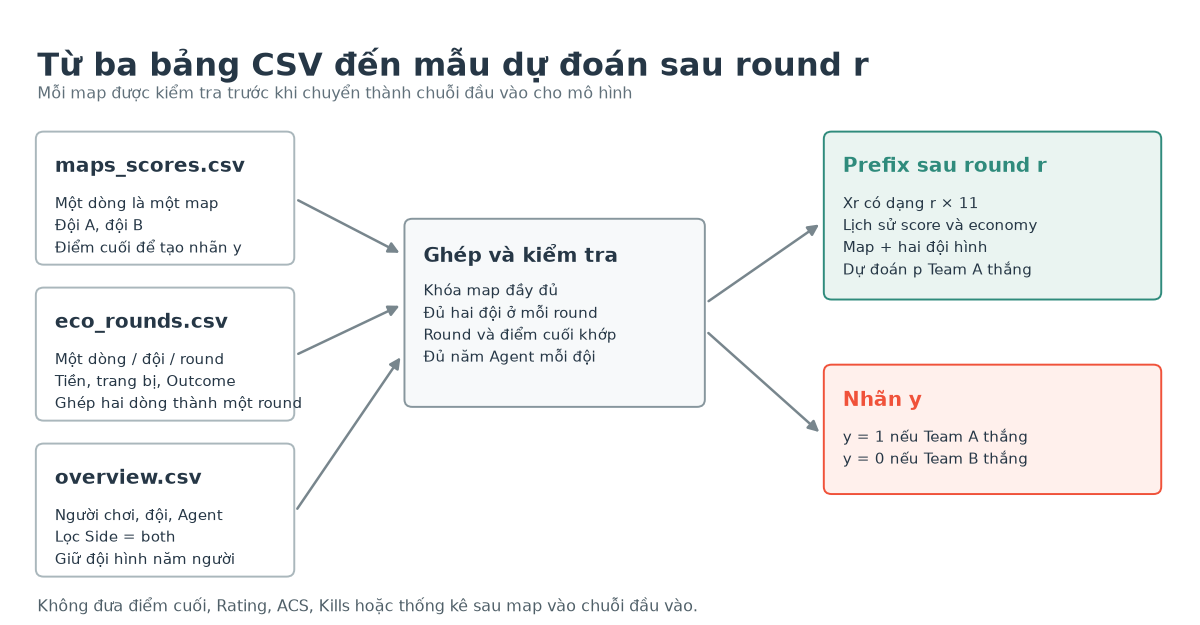

In [13]:
# Sơ đồ thể hiện ba nguồn dữ liệu, cách ghép và đầu ra của bài toán.

fig, ax = plt.subplots(figsize=(12.1, 6.35))
ax.set_xlim(0, 12.1)
ax.set_ylim(0, 6.35)
ax.axis("off")
fig.patch.set_facecolor("white")
ax.text(
    0.28,
    5.93,
    "Từ ba bảng CSV đến mẫu dự đoán sau round r",
    fontsize=23,
    fontweight="bold",
    color="#263746",
    va="top",
)
ax.text(
    0.28,
    5.53,
    "Mỗi map được kiểm tra trước khi chuyển thành chuỗi đầu vào cho mô hình",
    fontsize=11.5,
    color="#60707A",
    va="top",
)


def draw_card(
    x, y, w, h, title, lines, fill="white", edge="#AAB7BC", title_color="#263746"
):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.015,rounding_size=0.08",
            linewidth=1.4,
            edgecolor=edge,
            facecolor=fill,
        )
    )
    ax.text(
        x + 0.18,
        y + h - 0.26,
        title,
        fontsize=14.2,
        fontweight="bold",
        color=title_color,
        va="top",
    )
    ax.text(
        x + 0.18,
        y + h - 0.65,
        "\n".join(lines),
        fontsize=10.9,
        color="#263746",
        va="top",
        linespacing=1.45,
    )


draw_card(
    0.28,
    3.58,
    2.62,
    1.42,
    "maps_scores.csv",
    ["Một dòng là một map", "Đội A, đội B", "Điểm cuối để tạo nhãn y"],
)
draw_card(
    0.28,
    1.88,
    2.62,
    1.42,
    "eco_rounds.csv",
    [
        "Một dòng / đội / round",
        "Tiền, trang bị, Outcome",
        "Ghép hai dòng thành một round",
    ],
)
draw_card(
    0.28,
    0.18,
    2.62,
    1.42,
    "overview.csv",
    ["Người chơi, đội, Agent", "Lọc Side = both", "Giữ đội hình năm người"],
)
draw_card(
    4.06,
    2.03,
    3.05,
    2.02,
    "Ghép và kiểm tra",
    [
        "Khóa map đầy đủ",
        "Đủ hai đội ở mỗi round",
        "Round và điểm cuối khớp",
        "Đủ năm Agent mỗi đội",
    ],
    fill="#F7F9FA",
    edge="#87969D",
)
draw_card(
    8.36,
    3.2,
    3.43,
    1.8,
    "Prefix sau round r",
    [
        "Xr có dạng r × 11",
        "Lịch sử score và economy",
        "Map + hai đội hình",
        "Dự đoán p Team A thắng",
    ],
    fill="#EAF4F1",
    edge="#2F8B7C",
    title_color="#2F8B7C",
)
draw_card(
    8.36,
    1.08,
    3.43,
    1.38,
    "Nhãn y",
    ["y = 1 nếu Team A thắng", "y = 0 nếu Team B thắng"],
    fill="#FFF0EC",
    edge="#F0523A",
    title_color="#F0523A",
)


def draw_arrow(x1, y1, x2, y2):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            mutation_scale=16,
            linewidth=1.8,
            color="#78868D",
        )
    )


draw_arrow(2.93, 4.28, 4.02, 3.68)
draw_arrow(2.93, 2.58, 4.02, 3.13)
draw_arrow(2.93, 0.88, 4.02, 2.58)
draw_arrow(7.14, 3.15, 8.32, 4.02)
draw_arrow(7.14, 2.84, 8.32, 1.72)
ax.text(
    0.28,
    -0.06,
    "Không đưa điểm cuối, Rating, ACS, Kills hoặc thống kê sau map vào chuỗi đầu vào.",
    fontsize=11.2,
    color="#4F5F68",
    va="top",
)
save_figure(fig, "hinh_03_pipeline.png")

,Map gốc,Map giữ lại
season,,
2023,830,771
2024,1104,815


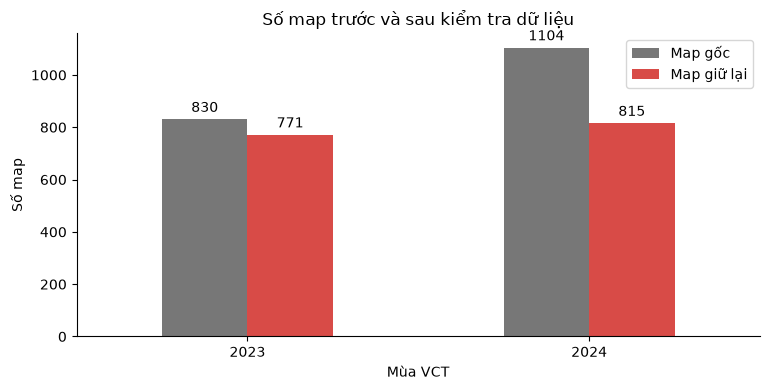

In [14]:
# Tạo bảng số map gốc và giữ lại từ các DataFrame đang có.
map_counts = pd.DataFrame(
    {
        "Map gốc": scores_raw.groupby("season").size(),
        "Map giữ lại": round_table.groupby("season")["map_id"].nunique(),
    }
)
# Bảng nguồn của Hình 4 cũng được hiển thị để kiểm tra số cột biểu đồ.
display(map_counts)
# Tạo một vùng vẽ vừa với khổ trang Word.
fig, ax = plt.subplots(figsize=(7.8, 4.0))
# plot.bar tạo hai cột cạnh nhau cho mỗi mùa.
map_counts.plot.bar(ax=ax, color=[COLORS["neutral"], COLORS["main"]], rot=0)
# Nhãn giá trị thật trên đầu cột để đọc trực tiếp số map.
for container in ax.containers:
    ax.bar_label(container, padding=3)
# Tiêu đề mô tả đúng ý nghĩa hình, không gọi đây là kết quả mô hình.
ax.set(title="Số map trước và sau kiểm tra dữ liệu", xlabel="Mùa VCT", ylabel="Số map")
# Lưu file tái tạo Hình 4 của báo cáo.
save_figure(fig, "hinh_04_so_map.png")

## Một map thật và 11 đặc trưng mỗi round

Các cột `score_A`, `score_B` là tỷ số sau round; `round_win_A/B` là kết quả của round đó; `loadout_A/B`, `credits_A/B` là số tiền gốc; `buy_level_A/B` là mã mức trang bị. `rounds_seen` là số round từ đầu map đến hiện tại. Tên map và hai đội hình là input cố định, không lặp thành số tiền trong 11 cột này.

In [15]:
# Chọn một map thật đầu tiên để theo dõi xuyên suốt các bước xử lý.
example_map_id = str(round_table.iloc[0]["map_id"])
# eq lọc đúng map; sort_values bảo đảm đi từ round 1 lên.
example_map = (
    round_table.loc[round_table["map_id"].eq(example_map_id)]
    .sort_values("Round Number")
    .reset_index(drop=True)
)
# Tên đội và bản đồ giúp người đọc nhận ra dòng dữ liệu đang xem.
print(example_map.iloc[0][["Team A", "Team B", "Map"]].to_dict())
# Hiển thị 8 round đầu ở đơn vị gốc, chưa chia thang đo.
display(example_map[ROUND_FEATURES].head(8))

{'Team A': 'KRÜ Esports', 'Team B': 'LEVIATÁN', 'Map': 'Ascent'}


,rounds_seen,score_A,score_B,round_win_A,loadout_A,credits_A,buy_level_A,round_win_B,loadout_B,credits_B,buy_level_B
0,1,0,1,0,3900.0,300.0,0,1,3200.0,400.0,0
1,2,0,2,0,4300.0,8000.0,0,1,16100.0,1100.0,2
2,3,1,2,1,20900.0,500.0,3,0,12200.0,13800.0,2
3,4,2,2,1,23000.0,12400.0,3,0,19400.0,4600.0,2
4,5,2,3,0,23100.0,21100.0,3,1,13100.0,9000.0,2
5,6,2,4,0,23000.0,10700.0,3,1,22100.0,9100.0,3
6,7,3,4,1,21600.0,4100.0,3,0,22500.0,12800.0,3
7,8,4,4,1,23000.0,10700.0,3,0,18300.0,6100.0,2


## Bảng 11 đặc trưng mà GRU nhận ở mỗi round

Bảng này nối trực tiếp tên cột trong code với ý nghĩa nghiệp vụ. `score_A` và `score_B` là tỷ số **sau** round đang xét; `round_win_A` và `round_win_B` chỉ là kết quả của round đó. `target` không nằm trong 11 đặc trưng vì đó là nhãn cuối map.

Đơn vị tiền giữ ở credits thật trong bảng kiểm tra, sau đó mới chia thang khi tạo `history`. Cách làm này giúp đọc dữ liệu không bị nhầm giữa giá trị gốc và số đã chuẩn hóa.


In [16]:
# Tạo bảng giải thích đúng thứ tự 11 cột trong một bước thời gian.
feature_spec = pd.DataFrame(
    [
        {
            "Đặc trưng": "rounds_seen",
            "Ý nghĩa": "Số round đã quan sát từ đầu map",
            "Đơn vị trước chuẩn hóa": "round",
        },
        {
            "Đặc trưng": "score_A / score_B",
            "Ý nghĩa": "Tỷ số hiện tại của hai đội sau round",
            "Đơn vị trước chuẩn hóa": "round thắng",
        },
        {
            "Đặc trưng": "round_win_A / round_win_B",
            "Ý nghĩa": "Đội nào thắng round vừa kết thúc",
            "Đơn vị trước chuẩn hóa": "0 hoặc 1",
        },
        {
            "Đặc trưng": "loadout_A / loadout_B",
            "Ý nghĩa": "Giá trị trang bị của mỗi đội",
            "Đơn vị trước chuẩn hóa": "credits",
        },
        {
            "Đặc trưng": "credits_A / credits_B",
            "Ý nghĩa": "Credits còn lại của mỗi đội",
            "Đơn vị trước chuẩn hóa": "credits",
        },
        {
            "Đặc trưng": "buy_level_A / buy_level_B",
            "Ý nghĩa": "Mức Eco, Semi-eco, Semi-buy hoặc Full buy",
            "Đơn vị trước chuẩn hóa": "0 đến 3",
        },
    ]
)
display(feature_spec)

,Đặc trưng,Ý nghĩa,Đơn vị trước chuẩn hóa
0,rounds_seen,Số round đã quan sát từ đầu map,round
1,score_A / score_B,Tỷ số hiện tại của hai đội sau round,round thắng
2,round_win_A / round_win_B,Đội nào thắng round vừa kết thúc,0 hoặc 1
3,loadout_A / loadout_B,Giá trị trang bị của mỗi đội,credits
4,credits_A / credits_B,Credits còn lại của mỗi đội,credits
5,buy_level_A / buy_level_B,"Mức Eco, Semi-eco, Semi-buy hoặc Full buy",0 đến 3


## Chuẩn hóa thang đo và tạo prefix

**Prefix** là đoạn lịch sử từ round 1 tới round hiện tại. Sau round 3, đầu vào là ma trận 3 × 11; sau round 4 là 4 × 11. Cả hai có chung nhãn cuối map nhưng khác lượng thông tin được quan sát. Round cuối bị bỏ vì map đã kết thúc.

Chia tỷ số và số round cho 20; tiền cho 10.000; mức trang bị cho 3. Đây là phép đổi thang **cố định**, không học từ test và không bảo đảm mọi số nằm giữa 0 và 1: hiệp phụ hoặc trang bị trên 10.000 vẫn có thể cho giá trị lớn hơn 1. Không được gọi đây là Min-Max scaling.

In [17]:
def scale_history(frame):
    """Đưa các cột về thang gần nhau trước khi đưa vào GRU."""

    # copy để không sửa bảng round_table ở đơn vị credits dễ đọc.
    values = frame[ROUND_FEATURES].to_numpy(dtype="float32").copy()
    # Số round và điểm hiện tại thường quanh 20, chia cho 20.
    values[:, [0, 1, 2]] /= 20.0
    # Loadout và credits có đơn vị nghìn, chia cho 10.000.
    values[:, [4, 5, 8, 9]] /= 10000.0
    # buy_level nằm trong 0..3, chia cho 3.
    values[:, [6, 10]] /= 3.0
    return values


# Một phần tử samples là lịch sử của một map tại một thời điểm dự đoán.
samples = []
for map_id, map_frame in round_table.groupby("map_id", sort=False):
    # Mỗi map là một chuỗi riêng, không nối lịch sử sang map khác.
    map_frame = map_frame.sort_values("Round Number").reset_index(drop=True)
    # states giữ các round đã chuẩn hóa theo đúng thứ tự từ đầu map.
    states = scale_history(map_frame)
    # Đội hình và nhãn không đổi trong map, nên đọc từ dòng đầu.
    first = map_frame.iloc[0]
    # Không tạo mẫu sau round cuối vì khi đó kết quả đã hoàn toàn lộ.
    for end in range(MIN_ROUND, len(map_frame)):
        current = map_frame.iloc[end - 1]
        samples.append(
            {
                "map_id": str(map_id),
                "match_group": str(first["match_group"]),
                "season": int(first["season"]),
                "round": int(current["Round Number"]),
                # [:end] chỉ lấy quá khứ đến round end, không lấy round tương lai.
                "history": states[:end].tolist(),
                "agents_A": list(first["squad_A"]),
                "agents_B": list(first["squad_B"]),
                "map": str(first["Map"]),
                "team_A": str(first["Team A"]),
                "team_B": str(first["Team B"]),
                "score_A": int(current["score_A"]),
                "score_B": int(current["score_B"]),
                "target": int(first["target"]),
                "final_score_A": int(first["Team A Score"]),
                "final_score_B": int(first["Team B Score"]),
                "economy": {
                    "loadout_A": float(current["loadout_A"]),
                    "loadout_B": float(current["loadout_B"]),
                    "credits_A": float(current["credits_A"]),
                    "credits_B": float(current["credits_B"]),
                    "buy_A": str(current["Type_A"]),
                    "buy_B": str(current["Type_B"]),
                },
            }
        )

example_prefix = samples[0]
print(
    "Số prefix:",
    len(samples),
    "Kích thước prefix đầu:",
    np.asarray(example_prefix["history"]).shape,
)
display(pd.DataFrame(example_prefix["history"], columns=ROUND_FEATURES))

Số prefix: 29015 Kích thước prefix đầu: (3, 11)


,rounds_seen,score_A,score_B,round_win_A,loadout_A,credits_A,buy_level_A,round_win_B,loadout_B,credits_B,buy_level_B
0,0.05,0.00,0.05,0.0,0.39,0.03,0.0,1.0,0.32,0.04,0.000000
1,0.10,0.00,0.10,0.0,0.43,0.80,0.0,1.0,1.61,0.11,0.666667
2,0.15,0.05,0.10,1.0,2.09,0.05,1.0,0.0,1.22,1.38,0.666667


## Chia huấn luyện, kiểm định và kiểm tra

**Train** dùng cập nhật trọng số; **validation** chọn checkpoint và dừng sớm; **test** chỉ đánh giá sau khi đã huấn luyện. Năm 2023 được chia ngẫu nhiên **theo loạt trận**, seed 42, khoảng 20% loạt trận làm validation. Năm 2024 được giữ riêng để kiểm tra khác mùa. Tỷ lệ 20% áp dụng trên số loạt trận, không nhất thiết đúng 20% số map hoặc prefix.

In [18]:
# Gom prefix cùng một loạt BO3/BO5 để tránh cùng trận xuất hiện ở hai tập.
by_group = {}
for sample in samples:
    by_group.setdefault(sample["match_group"], []).append(sample)

# Chỉ xáo trộn các loạt trận 2023; toàn bộ 2024 được giữ làm test.
groups_2023 = sorted(
    group for group, rows in by_group.items() if rows[0]["season"] == 2023
)
rng = np.random.default_rng(SEED)
rng.shuffle(groups_2023)
validation_count = max(1, round(len(groups_2023) * 0.2))
validation_groups = set(groups_2023[:validation_count])
train_groups = set(groups_2023[validation_count:])

train_rows = [row for row in samples if row["match_group"] in train_groups]
validation_rows = [row for row in samples if row["match_group"] in validation_groups]
test_rows = [row for row in samples if row["season"] == 2024]

map_sets = [
    set(row["map_id"] for row in rows)
    for rows in (train_rows, validation_rows, test_rows)
]
assert all(map_sets[i].isdisjoint(map_sets[j]) for i, j in ((0, 1), (0, 2), (1, 2)))
assert train_groups.isdisjoint(validation_groups)

split_summary = pd.DataFrame(
    [
        {
            "Tập": name,
            "Số prefix": len(rows),
            "Số map": len({r["map_id"] for r in rows}),
            "Số loạt trận": len({r["match_group"] for r in rows}),
        }
        for name, rows in (
            ("Huấn luyện", train_rows),
            ("Kiểm định", validation_rows),
            ("Kiểm tra", test_rows),
        )
    ]
)
display(split_summary)

,Tập,Số prefix,Số map,Số loạt trận
0,Huấn luyện,11450,623,250
1,Kiểm định,2753,148,62
2,Kiểm tra,14812,815,320


,Tập,Prefix A thua,Prefix A thắng,Map A thua,Map A thắng
0,Huấn luyện,5588,5862,300,323
1,Kiểm định,1394,1359,75,73
2,Kiểm tra,7163,7649,389,426


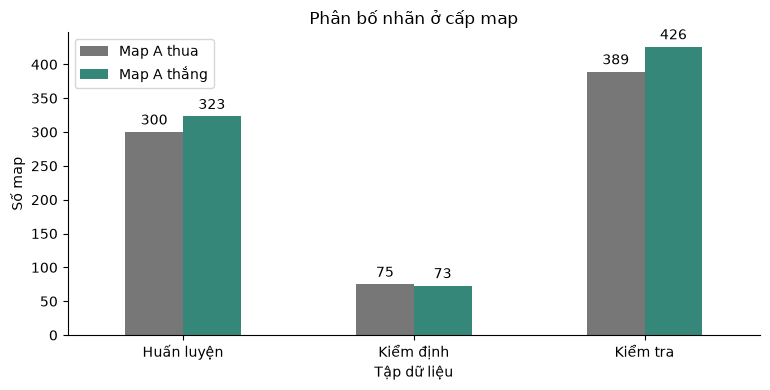

In [19]:
# Đếm nhãn ở cả cấp prefix và cấp map để không nhầm 14.812 mẫu với 14.812 trận.
class_rows = []
# Duyệt từng tập, không trộn train/test để chọn cách cân bằng lớp.
for name, rows in (
    ("Huấn luyện", train_rows),
    ("Kiểm định", validation_rows),
    ("Kiểm tra", test_rows),
):
    # Chỉ lấy metadata cần cho thống kê nhãn.
    labels = pd.DataFrame(
        [{"map_id": r["map_id"], "target": r["target"]} for r in rows]
    )
    # Một map tạo nhiều prefix, nên cần drop_duplicates ở cấp map.
    maps = labels.drop_duplicates("map_id")
    # Ghi hai mức đếm vào cùng một bảng để người đọc tự đối chiếu.
    class_rows.append(
        {
            "Tập": name,
            "Prefix A thua": int(labels["target"].eq(0).sum()),
            "Prefix A thắng": int(labels["target"].eq(1).sum()),
            "Map A thua": int(maps["target"].eq(0).sum()),
            "Map A thắng": int(maps["target"].eq(1).sum()),
        }
    )
# Class distribution là phân bố nhãn thật, không phải xác suất model dự đoán.
class_distribution = pd.DataFrame(class_rows)
# Kiểm tra dữ liệu có lệch lớp quá mạnh không.
display(class_distribution)
# Vẽ số map của từng lớp, không vẽ prefix như các trận độc lập.
fig, ax = plt.subplots(figsize=(7.8, 4.0))
# Hai màu khác nhau cho A thua và A thắng; rot=0 giữ nhãn tập ngang.
class_distribution.set_index("Tập")[["Map A thua", "Map A thắng"]].plot.bar(
    ax=ax, color=[COLORS["neutral"], COLORS["secondary"]], rot=0
)
# Hiển thị số map trên đầu mỗi cột.
for container in ax.containers:
    ax.bar_label(container, padding=3)
# Nhãn trục thể hiện rõ đang đếm map chứ không phải prefix.
ax.set(title="Phân bố nhãn ở cấp map", xlabel="Tập dữ liệu", ylabel="Số map")
# File hình được dùng trong phần bổ sung của báo cáo.
save_figure(fig, "phan_bo_nhan.png")

## Mã hóa map và Agent chỉ từ tập huấn luyện

Mạng không nhận chữ `Lotus` hay `jett` trực tiếp. Từ điển đổi chữ thành chỉ số; embedding tra chỉ số thành vector có thể học. Chỉ fit từ điển trên train. Giá trị mới ở validation/test nhận chỉ số 0 (**unknown**), không thêm ngược vào train. Embedding unknown trong mô hình hiện tại không được huấn luyện trực tiếp từ mẫu train nếu train không có unknown; đó là giới hạn cần nêu, không phải mạng tự biết Agent mới.

In [20]:
# Vocabulary chỉ được học từ train; index 0 dành cho giá trị chưa từng thấy.
def _fit_vocab(samples, field):
    # field là tên trường, chẳng hạn map. Set bỏ tên trùng, sorted cố định thứ tự.
    values = sorted({str(sample[field]) for sample in samples})
    # enumerate đếm từ 0. Cộng 1 để chừa mã 0 cho giá trị mới ở validation/test.
    return {value: index + 1 for index, value in enumerate(values)}


def _fit_agent_vocab(samples):
    values = {
        str(agent)
        for sample in samples
        for side in ("agents_A", "agents_B")
        for agent in sample[side]
    }
    return {value: index + 1 for index, value in enumerate(sorted(values))}


def _one_hot(value, vocabulary):
    # Map chỉ bật một vị trí trong vector.
    vector = np.zeros(len(vocabulary), dtype=np.float32)
    index = vocabulary.get(value)
    if index is not None:
        vector[index - 1] = 1.0
    return vector


def _multi_hot(values, vocabulary):
    # Đội hình có năm Agent nên có thể bật nhiều vị trí cùng lúc.
    vector = np.zeros(len(vocabulary), dtype=np.float32)
    for value in values:
        index = vocabulary.get(str(value))
        if index is not None:
            vector[index - 1] = 1.0
    return vector


@dataclass(frozen=True)
class SequenceVocabulary:
    maps: dict
    agents: dict


def build_sequence_vocabulary(train):
    return SequenceVocabulary(
        maps=_fit_vocab(train, "map"),
        agents=_fit_agent_vocab(train),
    )


vocabulary = build_sequence_vocabulary(train_rows)
display(pd.DataFrame(sorted(vocabulary.maps.items()), columns=["Tên map", "Chỉ số"]))
display(pd.DataFrame(sorted(vocabulary.agents.items()), columns=["Agent", "Chỉ số"]))
unknown_summary = pd.DataFrame(
    [
        {
            "Tập": name,
            "Prefix có map mới": sum(r["map"] not in vocabulary.maps for r in rows),
            "Prefix có Agent mới": sum(
                any(
                    a not in vocabulary.agents
                    for side in ("agents_A", "agents_B")
                    for a in r[side]
                )
                for r in rows
            ),
        }
        for name, rows in (
            ("Huấn luyện", train_rows),
            ("Kiểm định", validation_rows),
            ("Kiểm tra", test_rows),
        )
    ]
)
display(unknown_summary)

,Tên map,Chỉ số
0,Ascent,1
1,Bind,2
2,Fracture,3
3,Haven,4
4,Icebox,5
5,Lotus,6
6,Pearl,7
7,Split,8


,Agent,Chỉ số
0,astra,1
1,breach,2
2,brimstone,3
3,chamber,4
4,cypher,5
5,fade,6
6,gekko,7
7,harbor,8
8,jett,9
9,kayo,10


,Tập,Prefix có map mới,Prefix có Agent mới
0,Huấn luyện,0,0
1,Kiểm định,0,0
2,Kiểm tra,3819,1307


## Tensor và batch có kích thước như thế nào

Tensor là mảng số mà PyTorch xử lý. Một batch có nhiều prefix dài ngắn khác nhau, nên phải **padding**: thêm 0 để các chuỗi cùng độ dài. `lengths` giữ số round thật. `pack_padded_sequence` giúp GRU bỏ phần 0 thêm vào, không coi đó là round đã chơi. `batch_first=True` đặt số mẫu ở chiều đầu: batch × số round × 11. `num_workers=0` chạy loader trong tiến trình hiện tại, thuận tiện với notebook trên Mac.

In [21]:
class PrefixDataset(Dataset):
    """Đổi từng prefix thành các tensor mà PyTorch hiểu được."""

    def __init__(self, rows, vocabulary):
        # rows chứa các mẫu prefix. vocabulary ánh xạ tên map và Agent sang số.
        self.rows = rows
        self.vocabulary = vocabulary

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        # Sắp xếp Agent để thứ tự dòng CSV không làm thay đổi đội hình.
        agents_a = [
            self.vocabulary.agents.get(str(v), 0) for v in sorted(row["agents_A"])
        ]
        agents_b = [
            self.vocabulary.agents.get(str(v), 0) for v in sorted(row["agents_B"])
        ]
        return {
            # float32 lưu số thực cho 11 đặc trưng của mỗi round.
            "history": torch.tensor(row["history"], dtype=torch.float32),
            "length": len(row["history"]),
            "map_id": self.vocabulary.maps.get(str(row["map"]), 0),
            # long là số nguyên 64 bit, dùng làm chỉ số tra bảng embedding.
            "agents_A": torch.tensor(agents_a, dtype=torch.long),
            "agents_B": torch.tensor(agents_b, dtype=torch.long),
            "target": float(row["target"]),
        }


def collate_prefix_batch(rows):
    # Prefix dài ngắn khác nhau nên phải thêm padding vào cuối các prefix ngắn.
    histories = pad_sequence(
        [row["history"] for row in rows], batch_first=True, padding_value=0.0
    )
    # lengths giúp GRU bỏ qua phần padding.
    lengths = torch.tensor([row["length"] for row in rows], dtype=torch.long)
    maps = torch.tensor([row["map_id"] for row in rows], dtype=torch.long)
    agents_a = torch.stack([row["agents_A"] for row in rows])
    agents_b = torch.stack([row["agents_B"] for row in rows])
    targets = torch.tensor([row["target"] for row in rows], dtype=torch.float32)
    return histories, lengths, maps, agents_a, agents_b, targets

In [22]:
# Dataset lấy từng prefix và đổi nó thành tensor; chưa huấn luyện mạng ở bước này.
train_dataset = PrefixDataset(train_rows, vocabulary)
# Lấy bốn mẫu đầu để nhìn shape mà không in toàn bộ dữ liệu.
preview_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_prefix_batch,
)
preview_batch = next(iter(preview_loader))
batch_names = ["history", "lengths", "map index", "agents A", "agents B", "target"]
batch_shapes = pd.DataFrame(
    [
        {"Tensor": name, "Kích thước": str(tuple(t.shape)), "Kiểu": str(t.dtype)}
        for name, t in zip(batch_names, preview_batch)
    ]
)
display(batch_shapes)
print("Độ dài thật:", preview_batch[1].tolist())

,Tensor,Kích thước,Kiểu
0,history,"(4, 6, 11)",torch.float32
1,lengths,"(4,)",torch.int64
2,map index,"(4,)",torch.int64
3,agents A,"(4, 5)",torch.int64
4,agents B,"(4, 5)",torch.int64
5,target,"(4,)",torch.float32


Độ dài thật: [3, 4, 5, 6]


## Mô hình đối chứng học dữ liệu như thế nào

Logistic Regression là mốc tuyến tính dễ giải thích. XGBoost và CatBoost là tập hợp cây học quan hệ phi tuyến. Cả ba nhận vector gồm: trạng thái hiện tại, trung bình lịch sử, thay đổi từ round đầu, tên map one-hot và đội hình multi-hot. One-hot bật một vị trí tên map; multi-hot bật nhiều vị trí Agent. Các vector này không giữ nguyên thứ tự mọi round như GRU.

`StandardScaler` chỉ fit trên train trong pipeline Logistic Regression. XGBoost/CatBoost dùng đặc trưng bảng, không cần cùng phép chuẩn hóa thống kê này. Các cấu hình cố định giữ nguyên với lần thực nghiệm trước; không dùng test để tinh chỉnh.

In [23]:
def _baseline_row(sample, map_vocab, agent_vocab):
    # Baseline không đọc thứ tự đầy đủ; chỉ giữ current, mean và change.
    history = np.asarray(sample["history"], dtype=np.float32)
    numeric = np.concatenate(
        [history[-1], history.mean(axis=0), history[-1] - history[0]]
    )
    return np.concatenate(
        [
            numeric,
            _one_hot(str(sample["map"]), map_vocab),
            _multi_hot(sample["agents_A"], agent_vocab),
            _multi_hot(sample["agents_B"], agent_vocab),
        ]
    ).astype(np.float32)


@dataclass(frozen=True)
class BaselineFeatures:
    train: np.ndarray
    validation: np.ndarray
    test: np.ndarray
    feature_names: list


def build_baseline_features(train, validation, test):
    map_vocab = _fit_vocab(train, "map")
    agent_vocab = _fit_agent_vocab(train)
    names = [f"current_{i}" for i in range(11)]
    names += [f"mean_{i}" for i in range(11)]
    names += [f"change_{i}" for i in range(11)]
    names += [f"map={value}" for value in sorted(map_vocab)]
    names += [f"agents_A={value}" for value in sorted(agent_vocab)]
    names += [f"agents_B={value}" for value in sorted(agent_vocab)]

    def matrix(rows):
        return np.vstack([_baseline_row(row, map_vocab, agent_vocab) for row in rows])

    return BaselineFeatures(matrix(train), matrix(validation), matrix(test), names)


def evaluate_probabilities(y_true, probabilities):
    """Tính metric cho xác suất; Log Loss và Brier càng thấp càng tốt."""

    y = np.asarray(list(y_true), dtype=np.int64)
    # Clip giúp Log Loss không gặp log(0) khi xác suất sát 0 hoặc 1.
    p = np.clip(np.asarray(list(probabilities), dtype=np.float64), 1e-6, 1 - 1e-6)
    result = {
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
        "brier": float(brier_score_loss(y, p)),
        "accuracy": float(accuracy_score(y, p >= 0.5)),
        "f1": float(f1_score(y, p >= 0.5, zero_division=0)),
    }
    result["roc_auc"] = (
        float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else float("nan")
    )
    return result

In [24]:
# Dùng cùng vocabulary fit trên train để baseline không nhìn trước test.
baseline_features = build_baseline_features(train_rows, validation_rows, test_rows)
readable_names = [
    f"{group}_{feature}"
    for group in ("current", "mean", "change")
    for feature in ROUND_FEATURES
]
readable_names += baseline_features.feature_names[33:]
display(pd.DataFrame(baseline_features.train[:3], columns=readable_names))
print("Ma trận baseline train:", baseline_features.train.shape)

# y là nhãn cuối map; không đưa y vào ma trận input X.
y_train = np.asarray([r["target"] for r in train_rows], dtype=np.int64)
y_validation = np.asarray([r["target"] for r in validation_rows], dtype=np.int64)
y_test = np.asarray([r["target"] for r in test_rows], dtype=np.int64)

,current_rounds_seen,current_score_A,current_score_B,current_round_win_A,current_loadout_A,current_credits_A,current_buy_level_A,current_round_win_B,current_loadout_B,current_credits_B,...,agents_B=neon,agents_B=omen,agents_B=phoenix,agents_B=raze,agents_B=reyna,agents_B=sage,agents_B=skye,agents_B=sova,agents_B=viper,agents_B=yoru
0,0.15,0.05,0.10,1.0,1.83,0.09,0.666667,0.0,1.83,1.62,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.20,0.05,0.15,0.0,1.88,0.37,0.666667,1.0,2.26,0.69,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.25,0.05,0.20,0.0,0.47,0.90,0.000000,1.0,2.38,1.65,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


Ma trận baseline train: (11450, 83)


In [25]:
# Đặt seed trước mọi bước model để lặp lại thứ tự khởi tạo PyTorch như script.
random.seed(SEED)
# Cố định NumPy khi các thuật toán dùng số ngẫu nhiên.
np.random.seed(SEED)
# Đặt seed tensor trước khi khởi tạo mạng và xáo trộn các batch.
torch.manual_seed(SEED)
# Không đổi cấu hình để chạy theo đúng thí nghiệm của repo.
baseline_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),  # Chỉ fit scaler khi gọi pipeline.fit trên train.
        LogisticRegression(
            max_iter=1000, C=0.5
        ),  # Tối đa 1000 vòng; C điều chỉnh regularization.
    ),
    "XGBoost": XGBClassifier(
        n_estimators=180,  # Tối đa 180 cây boosting.
        max_depth=4,  # Mỗi cây sâu tối đa 4 để hạn chế quá khớp.
        learning_rate=0.05,  # Mỗi cây mới đóng góp với hệ số 0,05.
        subsample=0.9,  # Mỗi cây lấy ngẫu nhiên 90% mẫu train.
        colsample_bytree=0.9,  # Mỗi cây dùng ngẫu nhiên 90% đặc trưng.
        eval_metric="logloss",  # Theo dõi sai số xác suất.
        tree_method="approx",  # Giữ cấu hình ổn định với XGBoost Homebrew hiện tại.
        n_jobs=1,  # Giới hạn một luồng CPU.
        random_state=SEED,  # Cố định ngẫu nhiên của XGBoost.
    ),
    "CatBoost": CatBoostClassifier(
        iterations=180,  # 180 vòng boosting.
        depth=5,  # Độ sâu cây tối đa 5.
        learning_rate=0.05,  # Hệ số cập nhật mỗi vòng.
        loss_function="Logloss",  # Mục tiêu phân loại xác suất nhị phân.
        eval_metric="Logloss",  # Cùng thước đo đánh giá với bài toán.
        verbose=False,  # Không in log từng vòng cho baseline.
        thread_count=1,  # Giới hạn một luồng CPU.
        random_seed=SEED,  # Cố định khởi tạo của CatBoost.
        allow_writing_files=False,  # Không tạo thư mục catboost_info.
    ),
}
# Danh sách metric được tính từ dự đoán thật.
results = []
# Lưu xác suất test của từng model theo cùng thứ tự test_rows.
test_predictions = {}
# Huấn luyện từng baseline lần lượt trên ma trận train.
for name, model in baseline_models.items():
    # fit chỉ nhận input train và target train.
    model.fit(baseline_features.train, y_train)
    # Cột 1 của predict_proba là xác suất Team A thắng map.
    validation_probability = model.predict_proba(baseline_features.validation)[:, 1]
    # Chỉ suy luận trên test; không fit lại bằng dữ liệu test.
    test_probability = model.predict_proba(baseline_features.test)[:, 1]
    # Mỗi vector có một xác suất cho mỗi prefix test.
    test_predictions[name] = test_probability
    # Tính metric chung cho tất cả mô hình, không ghi sẵn đáp án.
    results.append(
        {
            "model": name,
            "validation": evaluate_probabilities(y_validation, validation_probability),
            "test": evaluate_probabilities(y_test, test_probability),
        }
    )
    # Log Loss càng thấp càng tốt, in để xem tiến độ thực tế.
    print(name, "validation Log Loss:", round(results[-1]["validation"]["log_loss"], 4))

Logistic Regression validation Log Loss: 0.6347


XGBoost validation Log Loss: 0.5338


CatBoost validation Log Loss: 0.5506


## GRU cập nhật thông tin như thế nào

Ở round thứ `t`, GRU nhận vector `x_t` gồm 11 giá trị và trạng thái cũ `h_(t-1)`. Cổng cập nhật `z_t` quyết định giữ bao nhiêu thông tin mới; cổng reset `r_t` quyết định mức ảnh hưởng của lịch sử cũ khi tạo trạng thái ứng viên. Một cách viết ngắn gọn là:

`z_t = sigmoid(W_z x_t + U_z h_(t-1) + b_z)`

`r_t = sigmoid(W_r x_t + U_r h_(t-1) + b_r)`

`h_t = (1 - z_t) * n_t + z_t * h_(t-1)` với `n_t = tanh(W_h x_t + U_h * (r_t * h_(t-1)) + b_h)`

Trong code, `h_t` có 48 chiều. Khi đọc xong prefix, trạng thái cuối được ghép với embedding của map và đội hình hai đội rồi đưa qua prediction head để tạo logit. Công thức giúp giải thích cơ chế, còn trọng số `W`, `U`, `b` được học từ train chứ không gán thủ công.


## GRU đọc chuỗi và ghép hai đội hình

GRU đọc lần lượt round 1, 2,... và cập nhật **trạng thái ẩn** là vector tóm tắt lịch sử. Trạng thái 48 chiều được ghép với embedding map 8 chiều và hai vector đội hình 12 chiều: tổng 80 số. Lớp dự đoán đổi 80 → 48 → 1. `ReLU` tạo phi tuyến; `Dropout(0.1)` bỏ ngẫu nhiên 10% phần tử khi train, được tắt khi suy luận. Không phải bỏ 10% dòng dữ liệu.

Biến thể **mean** lấy trung bình năm embedding Agent. Biến thể **agent attention** học một điểm cho mỗi Agent rồi softmax thành trọng số. Attention ở đây đặt trên **năm Agent**, không phải chọn round quan trọng và không phải Transformer. Điểm attention chỉ phụ thuộc embedding Agent trong cấu trúc hiện tại, không trực tiếp phụ thuộc map hoặc hidden state; không thể đọc nó như tác động nhân quả của đặc vụ.

`input_size=11`: mỗi round có 11 giá trị. `hidden_size=48`: kích thước tóm tắt lịch sử. `batch_first=True`: chiều đầu là batch. `dim=1` ở vector đội hình là chiều năm Agent. `squeeze` bỏ chiều kích thước 1; `unsqueeze` thêm chiều để nhân trọng số đúng shape.

In [26]:
class WinProbabilityGRU(nn.Module):
    """GRU đọc chuỗi round rồi ghép embedding map và đội hình hai đội."""

    def __init__(
        self, map_count, agent_count, round_feature_count, use_agent_attention=True
    ):
        # Đăng ký các lớp con và trọng số để PyTorch có thể huấn luyện mạng.
        super().__init__()
        self.use_agent_attention = use_agent_attention
        # +1 vì index 0 đại diện cho giá trị chưa biết.
        self.map_embedding = nn.Embedding(map_count + 1, 8)
        self.agent_embedding = nn.Embedding(agent_count + 1, 12)
        # Lớp này chấm điểm từng Agent trong biến thể attention.
        self.agent_score = nn.Linear(12, 1)
        # GRU đọc mỗi round gồm 11 số và tạo hidden state 48 chiều.
        self.gru = nn.GRU(
            input_size=round_feature_count, hidden_size=48, batch_first=True
        )
        # Prediction head biến vector tổng hợp thành một logit.
        self.head = nn.Sequential(
            # 80 đầu vào = lịch sử 48 + map 8 + đội A 12 + đội B 12 chiều.
            nn.Linear(48 + 8 + 12 + 12, 48),
            nn.ReLU(),  # Giữ số dương, đổi số âm thành 0 để tạo tính phi tuyến.
            nn.Dropout(p=0.1),  # Khi train, tạm bỏ 10% phần tử để giảm quá khớp.
            nn.Linear(48, 1),  # Mỗi mẫu trả về một logit, chưa phải xác suất.
        )

    def _team_vector(self, agents):
        # agents có dạng batch × 5. Kết quả vectors có dạng batch × 5 × 12.
        vectors = self.agent_embedding(agents)
        if not self.use_agent_attention:
            # Mean coi năm Agent có trọng số như nhau.
            return vectors.mean(dim=1)
        # Attention học trọng số có tổng bằng 1 qua softmax.
        weights = torch.softmax(self.agent_score(vectors).squeeze(-1), dim=1)
        # unsqueeze(-1) thêm chiều để nhân từng vector với trọng số của Agent đó.
        # sum(dim=1) cộng theo năm Agent, còn lại batch × 12.
        return (vectors * weights.unsqueeze(-1)).sum(dim=1)

    def forward(self, histories, lengths, maps, agents_a, agents_b):
        # Pack để GRU không học từ padding.
        packed = pack_padded_sequence(
            histories, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        # Bỏ output từng bước (_), chỉ lấy hidden cuối để tóm tắt prefix.
        _, hidden = self.gru(packed)
        # Ghép hidden state với map embedding và hai vector đội hình.
        joined = torch.cat(
            [
                hidden[-1],
                self.map_embedding(maps),
                self._team_vector(agents_a),
                self._team_vector(agents_b),
            ],
            dim=1,
        )
        # squeeze(1) đổi batch × 1 thành batch để khớp hình dạng nhãn.
        return self.head(joined).squeeze(1)

In [27]:
# Tóm tắt số tham số để kiểm tra mạng đã khởi tạo đúng cấu hình.
preview_model = WinProbabilityGRU(
    map_count=len(vocabulary.maps),
    agent_count=len(vocabulary.agents),
    round_feature_count=len(ROUND_FEATURES),
    use_agent_attention=False,
)
parameter_count = sum(parameter.numel() for parameter in preview_model.parameters())
print(preview_model)
print("Số tham số có thể học:", parameter_count)

WinProbabilityGRU(
  (map_embedding): Embedding(9, 8)
  (agent_embedding): Embedding(22, 12)
  (agent_score): Linear(in_features=12, out_features=1, bias=True)
  (gru): GRU(11, 48, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=80, out_features=48, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=48, out_features=1, bias=True)
  )
)
Số tham số có thể học: 13070


## Vòng huấn luyện học sâu chạy thật

Mạng trả **logit**, một số có thể âm hoặc dương. `BCEWithLogitsLoss` tính binary cross entropy trực tiếp trên logit để ổn định số học; không sigmoid lần nữa trước loss. Khi suy luận mới dùng `sigmoid` để đổi sang 0–1.

Một **epoch** là một lần quét train. Một **batch** tối đa 256 mẫu. `zero_grad` xóa gradient cũ; `backward` tính gradient; `optimizer.step` cập nhật trọng số. Gradient là hướng thay đổi tham số để giảm loss. Adam có learning rate 0,002. Mỗi epoch chấm validation; dừng khi không cải thiện ít nhất 0,0001 trong bốn epoch. Trọng số cuối được khôi phục từ checkpoint validation tốt nhất, không dùng checkpoint có test tốt nhất.

Ô dưới viết đầy đủ vòng train để có thể đặt điểm dừng và đọc lại. Nó giữ cùng cấu hình, thứ tự khởi tạo và cách chọn checkpoint của `scripts/train.py`.

In [28]:
# Kích thước batch cố định như thí nghiệm trong script.
BATCH_SIZE = 256
# Quét dữ liệu tối đa 18 lần; early stopping có thể dừng trước đó.
MAX_EPOCHS = 18
# Dừng khi 4 epoch liên tiếp không đủ cải thiện validation Log Loss.
PATIENCE = 4
# MPS dùng GPU Apple Silicon nếu có; CPU là đường chạy dự phòng.
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
# In thiết bị thật, không giả định máy đang dùng GPU.
print("Thiết bị huấn luyện:", device)


# Dùng cùng Dataset và collate đã giải thích ở bước tensor.
def make_loader(rows, shuffle):
    # Dataset biến từng dict mẫu thành tensor với vocabulary fit trên train.
    dataset = PrefixDataset(rows, vocabulary)
    # Train xáo trộn prefix, nhưng không đảo thứ tự round trong mỗi prefix.
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        collate_fn=collate_prefix_batch,
    )


# no_grad không ghi đồ thị gradient ở bước đánh giá, tiết kiệm bộ nhớ.
@torch.no_grad()
def predict_sequence(model, loader):
    # eval tắt dropout, không làm thay đổi trọng số.
    model.eval()
    # Gom xác suất từng batch theo thứ tự loader.
    values = []
    # _ là target được bỏ qua vì suy luận chỉ dùng input.
    for histories, lengths, maps, agents_a, agents_b, _ in loader:
        # Các input số lên cùng device; lengths vẫn ở CPU để pack chuỗi.
        logits = model(
            histories.to(device),
            lengths,
            maps.to(device),
            agents_a.to(device),
            agents_b.to(device),
        )
        # Sigmoid chỉ dùng lúc lấy xác suất, sau đó chuyển về CPU/NumPy.
        values.append(torch.sigmoid(logits).cpu().numpy())
    # Nối các vector theo chiều mẫu thành một vector đủ mọi prefix.
    return np.concatenate(values)


# Hàm train trả model tốt nhất theo validation và log của tất cả epoch đã chạy.
def train_gru(use_attention):
    # Kích thước embedding và GRU nằm trong class vừa hiển thị, không có model bí mật.
    model = WinProbabilityGRU(
        map_count=len(vocabulary.maps),
        agent_count=len(vocabulary.agents),
        round_feature_count=len(ROUND_FEATURES),
        use_agent_attention=use_attention,
    ).to(device)
    # Adam nhận toàn bộ tham số học được và tốc độ cập nhật 0,002.
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    # BCEWithLogitsLoss nhận logit, target dạng float 0/1.
    loss_function = nn.BCEWithLogitsLoss()
    # Loader train được xáo trộn từng epoch để giảm phụ thuộc thứ tự mẫu.
    train_loader = make_loader(train_rows, shuffle=True)
    # Validation không xáo trộn để xác suất khớp thứ tự y_validation.
    validation_loader = make_loader(validation_rows, shuffle=False)
    # Bắt đầu với vô hạn để loss hữu hạn đầu tiên được lưu.
    best_loss = float("inf")
    # Chưa có checkpoint trước khi model chạy ít nhất một epoch.
    best_state = None
    # Số epoch liên tiếp chưa cải thiện đủ.
    wait = 0
    # Lưu lịch sử để vẽ biểu đồ loss, không ghi tay kết quả.
    training_history = []
    # range bắt đầu từ 1 để số epoch hiển thị dễ đọc.
    for epoch in range(1, MAX_EPOCHS + 1):
        # train bật dropout và cho phép cập nhật trọng số.
        model.train()
        # Lưu loss từng batch để báo cáo trung bình cuối epoch như script.
        losses = []
        # Một vòng này xử lý toàn bộ batch train của một epoch.
        for histories, lengths, maps, agents_a, agents_b, targets in train_loader:
            # Xóa gradient batch trước, tránh cộng dồn ngoài ý muốn.
            optimizer.zero_grad()
            # Forward tính logit từ lịch sử round, map và đội hình, không nhận điểm cuối.
            logits = model(
                histories.to(device),
                lengths,
                maps.to(device),
                agents_a.to(device),
                agents_b.to(device),
            )
            # targets.to(device) đặt nhãn ở cùng thiết bị với logit.
            loss = loss_function(logits, targets.to(device))
            # Backpropagation tính gradient cho mọi trọng số tham gia dự đoán.
            loss.backward()
            # Adam cập nhật trọng số dựa trên gradient vừa tính.
            optimizer.step()
            # detach bỏ graph; cpu chuyển về máy để lưu một số Python.
            losses.append(float(loss.detach().cpu()))
        # Đánh giá trên validation, không gọi backward hoặc step ở đây.
        validation_probability = predict_sequence(model, validation_loader)
        # Cùng hàm Log Loss được dùng cho baseline và GRU.
        validation_loss = evaluate_probabilities(y_validation, validation_probability)[
            "log_loss"
        ]
        # Lưu cả loss train và validation của epoch thật.
        training_history.append(
            {
                "epoch": epoch,
                "train_loss": float(np.mean(losses)),
                "validation_log_loss": validation_loss,
            }
        )
        # In log để đọc được quá trình học và phát hiện loss bất thường.
        print(
            f"epoch {epoch:02d}: train={np.mean(losses):.4f}; validation={validation_loss:.4f}"
        )
        # Cần cải thiện hơn 0,0001 để tránh lưu checkpoint chỉ vì nhiễu rất nhỏ.
        if validation_loss < best_loss - 1e-4:
            # Cập nhật mốc validation tốt nhất.
            best_loss = validation_loss
            # clone lưu bản sao trên CPU, không giữ tham chiếu vào trọng số đang thay đổi.
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            # Có cải thiện thì reset số epoch chờ.
            wait = 0
        else:
            # Không cải thiện đủ thì tăng số epoch chờ.
            wait += 1
            # Đủ patience thì dừng, dù chưa quét hết 18 epoch.
            if wait >= PATIENCE:
                break
    # Dừng có thông báo nếu không có checkpoint hợp lệ, không âm thầm dùng model lỗi.
    if best_state is None:
        raise RuntimeError("Không có checkpoint GRU hợp lệ")
    # Khôi phục model ở epoch validation tốt nhất, không dùng epoch cuối tùy ý.
    model.load_state_dict(best_state)
    # Trả cả model và log để đánh giá/vẽ, không phải chỉ một số accuracy.
    return model, training_history

Thiết bị huấn luyện: mps


In [29]:
# Khởi tạo loader test đúng thời điểm như script, sau các baseline.
test_loader = make_loader(test_rows, shuffle=False)
# Lưu log epoch theo tên biến thể, giúp so sánh mean và attention.
training_histories = {}
# Mean được chọn làm model chính từ thiết kế; test không quyết định chọn biến thể.
for use_attention, name in ((False, "GRU + mean"), (True, "GRU + agent attention")):
    # Thông báo rõ biến thể đang chạy trong log.
    print("Huấn luyện", name)
    # use_attention=False dùng trung bình; True dùng trọng số Agent.
    model, history = train_gru(use_attention)
    # Chấm model đã khôi phục checkpoint trên validation trước.
    validation_probability = predict_sequence(
        model, make_loader(validation_rows, shuffle=False)
    )
    # Test chỉ suy luận sau khi train và early stopping hoàn tất.
    test_probability = predict_sequence(model, test_loader)
    # Lưu log đầy đủ của các epoch thực sự đã chạy.
    training_histories[name] = history
    # Lưu xác suất test cho các biểu đồ, không đọc demo.json để làm đáp án.
    test_predictions[name] = test_probability
    # Tính đúng cùng metric như baseline.
    results.append(
        {
            "model": name,
            "validation": evaluate_probabilities(y_validation, validation_probability),
            "test": evaluate_probabilities(y_test, test_probability),
            "training_history": history,
        }
    )
    # Log Loss test giúp xem chất lượng sau khi toàn bộ quá trình học hoàn tất.
    print("Test Log Loss:", results[-1]["test"]["log_loss"])
# Không chọn main model bằng argmin test: chỉ giữ mean như thiết kế ban đầu.
MAIN_MODEL = "GRU + mean"

Huấn luyện GRU + mean


epoch 01: train=0.6014; validation=0.5611


epoch 02: train=0.5175; validation=0.5410


epoch 03: train=0.4928; validation=0.5349


epoch 04: train=0.4749; validation=0.5414


...

epoch 07: train=0.4398; validation=0.5468


epoch 08: train=0.4331; validation=0.5436


epoch 09: train=0.4117; validation=0.5460


epoch 10: train=0.3973; validation=0.5579


Test Log Loss: 0.541101503018981


## Biểu đồ quá trình học

Loss train thấp dần cho thấy model học tốt hơn trên mẫu đã dùng cập nhật. Validation cho biết có tốt lên trên các map chưa fit hay không. Nếu train tiếp tục giảm mà validation tăng, đó là dấu hiệu quá khớp. Điểm được đánh dấu là checkpoint đã chọn theo cùng quy tắc cải thiện 0,0001, không theo test. Loss train là trung bình loss batch khi đang cập nhật; validation được tính khi eval, nên hai đường không hoàn toàn đồng nhất cách tính.

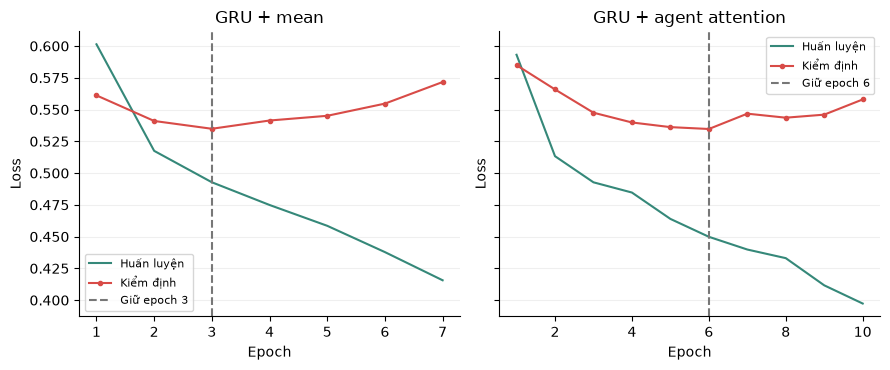

In [30]:
# Hai vùng vẽ cạnh nhau giúp thấy cả mean và attention.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8), sharey=True)
# Mỗi log lấy từ training_histories vừa chạy, không điền giá trị bằng tay.
for ax, (name, rows) in zip(axes, training_histories.items()):
    # Chuyển log epoch thành bảng để plot theo cột.
    history_frame = pd.DataFrame(rows)
    # Loss train trung bình các batch của epoch.
    ax.plot(
        history_frame["epoch"],
        history_frame["train_loss"],
        label="Huấn luyện",
        color=COLORS["secondary"],
    )
    # Loss validation trên toàn bộ prefix validation.
    ax.plot(
        history_frame["epoch"],
        history_frame["validation_log_loss"],
        label="Kiểm định",
        color=COLORS["main"],
        marker="o",
        markersize=3,
    )
    # Lặp đúng quy tắc lưu checkpoint thay vì lấy min khác ngưỡng.
    best_value, best_epoch = float("inf"), None
    # Theo dõi epoch nào thực sự được chấp nhận là tốt nhất.
    for row in rows:
        # Chỉ nhận cải thiện vượt ngưỡng 0,0001 như train_gru.
        if row["validation_log_loss"] < best_value - 1e-4:
            best_value, best_epoch = row["validation_log_loss"], row["epoch"]
    # Vạch dọc cho biết checkpoint được giữ lại.
    ax.axvline(
        best_epoch,
        color=COLORS["neutral"],
        linestyle="--",
        label=f"Giữ epoch {best_epoch}",
    )
    # Nhãn tránh viết chung là Accuracy vì đây là loss.
    ax.set(title=name, xlabel="Epoch", ylabel="Loss")
    # Mỗi biểu đồ có chú giải và lưới nhẹ để đọc được xu hướng.
    ax.legend(fontsize=8)
    # Chỉ lưới theo trục y để hình không bị rối.
    ax.grid(axis="y", alpha=0.2)
# Lưu biểu đồ để chèn vào phần giải thích early stopping.
save_figure(fig, "qua_trinh_hoc.png")

## Tính metric từ xác suất thật

**Log Loss** phạt nặng việc dự đoán sai nhưng quá tự tin. **Brier Score** là trung bình bình phương `(p − y)`. Hai số càng thấp càng tốt. **ROC-AUC** đo khả năng xếp mẫu thắng cao hơn mẫu thua. **Accuracy/F1** cần đổi xác suất thành lớp với ngưỡng 0,5; đây là số bổ sung, không thay thế đánh giá xác suất.

Các prefix cùng map có liên quan, nên không thể coi tổng prefix là số trận độc lập. Lần chạy một seed chưa đủ để chứng minh ưu thế có ý nghĩa thống kê. Test không dùng để chọn siêu tham số.

In [31]:
# Bảng metric được tính từ xác suất test vừa sinh ra, không nhập số bằng tay.
metrics = pd.DataFrame(
    [{"Mô hình": r["model"], **r["test"]} for r in results]
).set_index("Mô hình")
display(metrics.round(5))

# Mỗi model phải trả đủ một xác suất hợp lệ cho từng prefix test.
for name, probability in test_predictions.items():
    assert len(probability) == len(y_test)
    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()

# Tính ví dụ một mẫu để thấy metric được tính từ p và y như thế nào.
p_example = float(test_predictions[MAIN_MODEL][0])
y_example = int(y_test[0])
p_clipped = np.clip(p_example, 1e-6, 1 - 1e-6)
single_log_loss = -(
    y_example * np.log(p_clipped) + (1 - y_example) * np.log(1 - p_clipped)
)
single_brier = (p_example - y_example) ** 2
display(
    pd.DataFrame(
        [
            {
                "p": p_example,
                "y": y_example,
                "Log Loss một mẫu": single_log_loss,
                "Brier một mẫu": single_brier,
            }
        ]
    )
)

,log_loss,brier,accuracy,f1,roc_auc
Mô hình,,,,,
Logistic Regression,0.65030,0.20681,0.69883,0.71807,0.76457
XGBoost,0.53731,0.18096,0.72597,0.73777,0.80567
CatBoost,0.53495,0.17932,0.73191,0.74853,0.80953
GRU + mean,0.52666,0.17619,0.73697,0.75035,0.81603
GRU + agent attention,0.54110,0.18245,0.72367,0.73275,0.80213


,p,y,Log Loss một mẫu,Brier một mẫu
0,0.688925,0,1.167721,0.474618


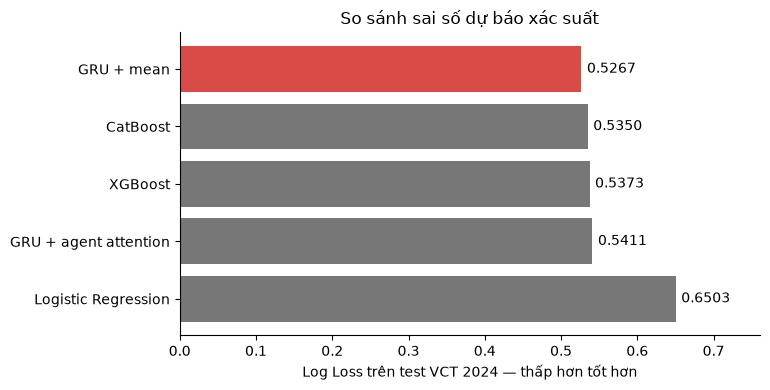

In [32]:
# Sắp xếp thấp tới cao để thấy model có Log Loss nhỏ hơn.
ordered = metrics["log_loss"].sort_values()
# Một vùng vẽ ngang phù hợp các tên model dài.
fig, ax = plt.subplots(figsize=(7.8, 4.0))
# Màu đỏ đánh dấu model chính mean, không đổi thứ tự dựa vào màu.
bars = ax.barh(
    ordered.index,
    ordered.values,
    color=[
        COLORS["main"] if n == MAIN_MODEL else COLORS["neutral"] for n in ordered.index
    ],
)
# Giá trị metric được lấy từ chiều dài cột, không gõ số lên biểu đồ.
ax.bar_label(bars, fmt="%.4f", padding=4)
# Model tốt hơn nằm trên; vẫn ghi rõ thấp hơn là tốt hơn.
ax.invert_yaxis()
# Tăng lề phải để nhãn số không vượt ra ngoài vùng vẽ.
ax.set_xlim(0, max(ordered.values) * 1.17)
# Nhãn thước đo chính xác, không gọi Log Loss là độ chính xác.
ax.set(
    title="So sánh sai số dự báo xác suất",
    xlabel="Log Loss trên test VCT 2024 — thấp hơn tốt hơn",
)
# Lưu biểu đồ so sánh Log Loss từ dự đoán vừa tính.
save_figure(fig, "hinh_06_log_loss.png")

## Chất lượng tại các mốc round

Sau round 6 và 12 vẫn có thể chưa rõ đội thắng. Sau round 18 chỉ còn những map đủ dài; không nên nói chất lượng tăng chỉ do thuật toán mà bỏ qua việc tập mẫu đã thay đổi. Với mỗi mốc, mỗi map chỉ đóng góp một prefix, giúp đối chiếu chất lượng theo thời điểm.

In [33]:
# Round của mỗi mẫu theo đúng thứ tự y_test và predictions.
test_rounds = np.asarray([r["round"] for r in test_rows])
# Bảng checkpoint ghi số mẫu và metric riêng tại từng mốc.
checkpoint_rows = []
# Mốc đánh giá giữ như báo cáo hiện tại.
for checkpoint in (6, 12, 18):
    # Boolean mask chỉ chọn prefix ngay sau round checkpoint.
    mask = test_rounds == checkpoint
    # Chấm tất cả model trên cùng những mẫu có mặt tại mốc đó.
    for name, probability in test_predictions.items():
        # Không tạo số liệu giả nếu một mốc không có mẫu.
        if mask.any():
            checkpoint_rows.append(
                {
                    "Round": checkpoint,
                    "Mô hình": name,
                    "Số prefix": int(mask.sum()),
                    **evaluate_probabilities(y_test[mask], probability[mask]),
                }
            )
# Mỗi dòng là metric của một model tại một mốc round.
checkpoint_table = pd.DataFrame(checkpoint_rows)
# Xem mean trước vì đây là model chính, bảng đầy đủ vẫn được lưu.
display(checkpoint_table.loc[checkpoint_table["Mô hình"].eq(MAIN_MODEL)].round(5))

,Round,Mô hình,Số prefix,log_loss,brier,accuracy,f1,roc_auc
3,6,GRU + mean,815,0.60577,0.20817,0.68466,0.69441,0.75161
8,12,GRU + mean,815,0.49923,0.16459,0.75828,0.76631,0.84169
13,18,GRU + mean,642,0.42702,0.13512,0.80685,0.81657,0.88760


,Round,Số prefix,log_loss,brier,roc_auc
3,6,815,0.60577,0.20817,0.75161
8,12,815,0.49923,0.16459,0.84169
13,18,642,0.42702,0.13512,0.88760


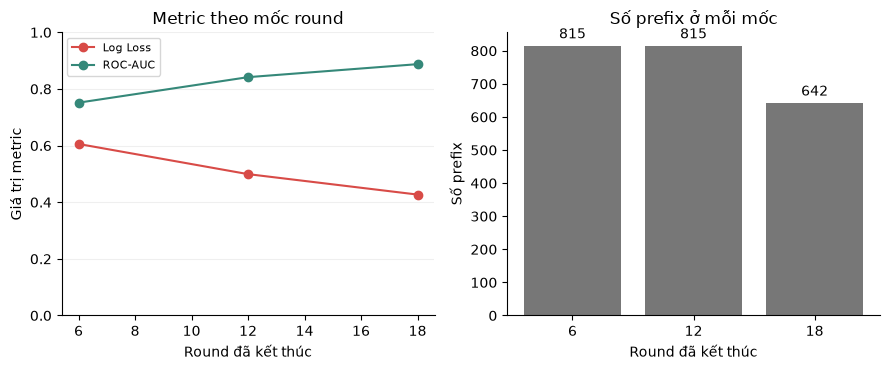

In [34]:
# Chọn riêng kết quả của mô hình chính để xem chất lượng thay đổi theo thời điểm.
main_checkpoints = checkpoint_table.loc[
    checkpoint_table["Mô hình"].eq(MAIN_MODEL)
].sort_values("Round")
display(
    main_checkpoints[["Round", "Số prefix", "log_loss", "brier", "roc_auc"]].round(5)
)

# Hai metric đều nằm trong khoảng dễ so sánh: Log Loss/Brier càng thấp càng tốt, ROC-AUC càng cao càng tốt.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8))
axes[0].plot(
    main_checkpoints["Round"],
    main_checkpoints["log_loss"],
    marker="o",
    color=COLORS["main"],
    label="Log Loss",
)
axes[0].plot(
    main_checkpoints["Round"],
    main_checkpoints["roc_auc"],
    marker="o",
    color=COLORS["secondary"],
    label="ROC-AUC",
)
axes[0].set(
    title="Metric theo mốc round",
    xlabel="Round đã kết thúc",
    ylabel="Giá trị metric",
    ylim=(0, 1),
)
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.2)
axes[1].bar(
    main_checkpoints["Round"].astype(str),
    main_checkpoints["Số prefix"],
    color=COLORS["neutral"],
)
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set(title="Số prefix ở mỗi mốc", xlabel="Round đã kết thúc", ylabel="Số prefix")
save_figure(fig, "hinh_12_checkpoint.png")

## Hiệu chỉnh xác suất và ROC

Biểu đồ hiệu chỉnh có **trục ngang là xác suất dự đoán**, **trục dọc là tỷ lệ thắng thật** trong nhóm. Đường chéo là mốc lý tưởng. `calibration_curve` của scikit-learn trả về **tỷ lệ thắng thật trước**, xác suất dự đoán trung bình sau; gán ngược sẽ khiến hình đọc sai. `n_bins=10`, `strategy="quantile"` chia thành khoảng mười nhóm gần bằng số lượng mẫu. Đây là kiểm tra calibration, không phải đã hiệu chỉnh lại model bằng temperature scaling.

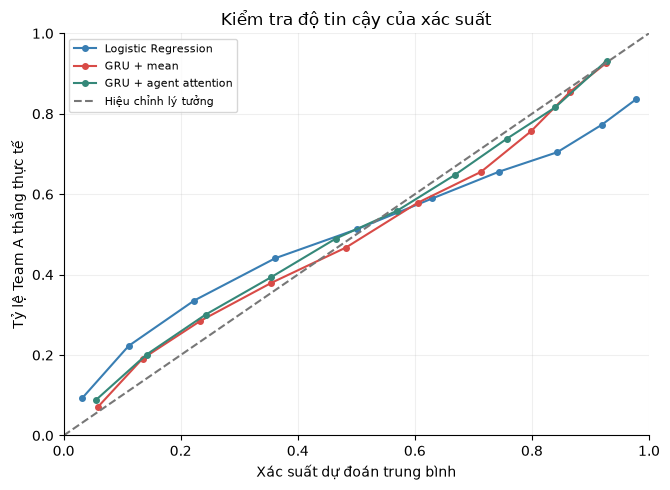

In [35]:
# Lưu tọa độ calibration để kiểm tra và có thể đồng bộ với web.
calibration_curves = {}
# Một vùng vẽ vuông giúp đường chéo 45 độ dễ đọc.
fig, ax = plt.subplots(figsize=(6.8, 5.0))
# Ba model giống các model trong biểu đồ báo cáo cũ.
for name, color in (
    ("Logistic Regression", "#397EB3"),
    (MAIN_MODEL, COLORS["main"]),
    ("GRU + agent attention", COLORS["secondary"]),
):
    # Quan trọng: sklearn trả prob_true trước, prob_pred sau.
    observed_frequency, predicted_probability = calibration_curve(
        y_test, test_predictions[name], n_bins=10, strategy="quantile"
    )
    # Ghi tên trường đúng ý nghĩa, không hoán đổi hai vector.
    calibration_curves[name] = {
        "predicted_probability": predicted_probability.tolist(),
        "observed_frequency": observed_frequency.tolist(),
    }
    # x là p model, y là tỷ lệ thắng thật, marker chỉ vị trí mỗi bin.
    ax.plot(
        predicted_probability,
        observed_frequency,
        marker="o",
        markersize=4,
        color=color,
        label=name,
    )
# Mốc lý tưởng p dự đoán bằng tỷ lệ thắng thật.
ax.plot(
    [0, 1], [0, 1], color=COLORS["neutral"], linestyle="--", label="Hiệu chỉnh lý tưởng"
)
# Hai trục cùng miền 0–1 để không làm méo cách đọc xác suất.
ax.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Xác suất dự đoán trung bình",
    ylabel="Tỷ lệ Team A thắng thực tế",
    title="Kiểm tra độ tin cậy của xác suất",
)
# Chú giải phân biệt các model, không chỉ dựa vào màu.
ax.legend(fontsize=8)
# Lưới nhẹ giúp đọc x/y ở từng bin.
ax.grid(alpha=0.2)
# Lưu biểu đồ độ tin cậy với hai trục đúng ý nghĩa.
save_figure(fig, "hinh_07_calibration.png")

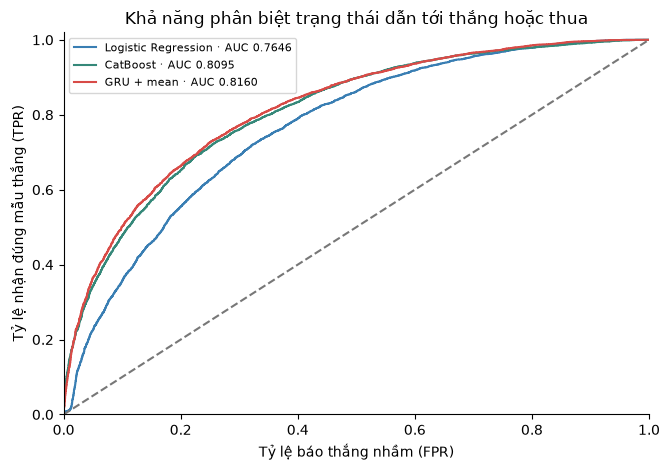

In [36]:
# ROC bổ sung cách đọc khả năng phân biệt, không thay thế calibration.
fig, ax = plt.subplots(figsize=(6.8, 4.8))
# Vẽ ba model tiêu biểu trên cùng tập test và thứ tự nhãn.
for name, color in (
    ("Logistic Regression", "#397EB3"),
    ("CatBoost", COLORS["secondary"]),
    (MAIN_MODEL, COLORS["main"]),
):
    # fpr là tỷ lệ báo thắng nhầm; tpr là tỷ lệ nhận đúng mẫu thắng.
    fpr, tpr, _ = roc_curve(y_test, test_predictions[name])
    # AUC lấy từ metric vừa tính, không lấy từ nhãn ảnh cũ.
    ax.plot(
        fpr, tpr, color=color, label=f"{name} · AUC {metrics.loc[name, 'roc_auc']:.4f}"
    )
# Đường chéo thể hiện mốc xếp hạng ngẫu nhiên.
ax.plot([0, 1], [0, 1], linestyle="--", color=COLORS["neutral"])
# Nhãn TPR/FPR có giải thích tiếng Việt đi kèm.
ax.set(
    xlim=(0, 1),
    ylim=(0, 1.02),
    xlabel="Tỷ lệ báo thắng nhầm (FPR)",
    ylabel="Tỷ lệ nhận đúng mẫu thắng (TPR)",
    title="Khả năng phân biệt trạng thái dẫn tới thắng hoặc thua",
)
# Chú giải đủ tên để không phải nhớ từng màu.
ax.legend(fontsize=8)
# Lưu hình phân biệt xác suất với phân loại.
save_figure(fig, "roc.png")

## Đường xác suất trên một map thật

Ví dụ hồi cứu cố định: Karmine Corp gặp FUT Esports, map Lotus, VCT 2024 EMEA Kickoff. Chọn map theo khóa, không chọn vì đường dự đoán đẹp. Mỗi điểm là p sau round vừa kết thúc. Điểm cuối map không được đưa vào history và không có điểm dự đoán sau round cuối. Nhìn vào đường này có thể xác định đoạn nên xem VOD, nhưng chưa giải thích được nguyên nhân chiến thuật nếu không có video/sự kiện.

Karmine Corp vs FUT Esports · Lotus


,Round,Điểm A,Điểm B,Xác suất A thắng,loadout_A,loadout_B,credits_A,credits_B,buy_A,buy_B,Thay đổi xác suất
0,3,2,1,0.7989,22000.0,21300.0,11400.0,400.0,Full buy: 20k+,Full buy: 20k+,NaN
1,4,3,1,0.8607,21600.0,18900.0,1600.0,4000.0,Full buy: 20k+,Semi-buy: 10-20k,0.0618
2,5,4,1,0.8895,23100.0,5600.0,7200.0,9200.0,Full buy: 20k+,Semi-eco: 5-10k,0.0288
3,6,5,1,0.9235,24600.0,21900.0,18800.0,500.0,Full buy: 20k+,Full buy: 20k+,0.0340
4,7,5,2,0.8842,24900.0,12600.0,23000.0,6600.0,Full buy: 20k+,Semi-buy: 10-20k,-0.0393
5,8,5,3,0.8432,23600.0,23100.0,11500.0,6700.0,Full buy: 20k+,Full buy: 20k+,-0.0409
6,9,5,4,0.8052,21200.0,21500.0,5300.0,6000.0,Full buy: 20k+,Full buy: 20k+,-0.0381
7,10,5,5,0.7443,19600.0,23000.0,2300.0,8400.0,Semi-buy: 10-20k,Full buy: 20k+,-0.0608


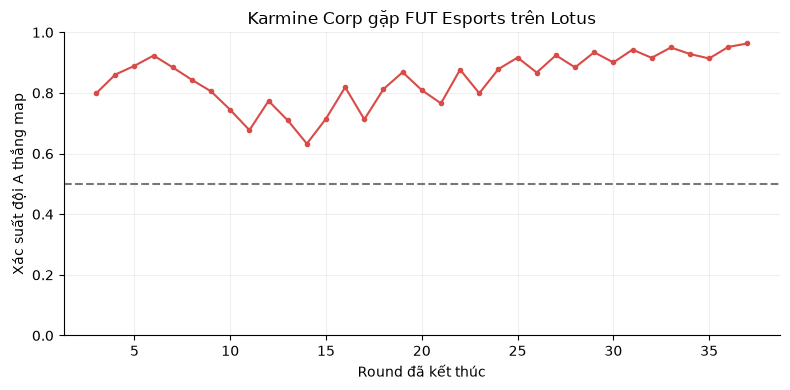

In [37]:
# Khóa ví dụ trùng với map minh họa trong báo cáo và demo hiện tại.
trajectory_map_id = "2024|Champions Tour 2024: EMEA Kickoff|Group Stage|Decider (A)|Karmine Corp vs FUT Esports|Lotus"
# Chọn vị trí của các prefix thuộc đúng map đó trong toàn bộ test.
trajectory_indices = [
    i for i, row in enumerate(test_rows) if row["map_id"] == trajectory_map_id
]
# Nếu nguồn thay đổi thì báo lỗi thay vì chọn map khác âm thầm.
assert trajectory_indices, "Không tìm thấy map minh họa trong test hiện tại"
# Mỗi dòng chứa điểm hiện tại, kinh tế và p suy luận sau round đó.
trajectory = pd.DataFrame(
    [
        {
            "Round": test_rows[i]["round"],
            "Điểm A": test_rows[i]["score_A"],
            "Điểm B": test_rows[i]["score_B"],
            "Xác suất A thắng": float(test_predictions[MAIN_MODEL][i]),
            **test_rows[i]["economy"],
        }
        for i in trajectory_indices
    ]
).sort_values("Round")
# diff đo thay đổi p so với prefix trước, không phải xác suất thắng round.
trajectory["Thay đổi xác suất"] = trajectory["Xác suất A thắng"].diff()
# In tên hai đội và nhãn cuối để nhận biết ví dụ, không đưa vào model lúc suy luận.
trajectory_first = test_rows[trajectory_indices[0]]
# Đây là thông tin kiểm tra sau trận, không phải input chuỗi.
print(
    trajectory_first["team_A"],
    "vs",
    trajectory_first["team_B"],
    "·",
    trajectory_first["map"],
)
# Bảng 8 round đầu giúp đối chiếu hình với con số thật.
display(trajectory.head(8).round(4))
# Một vùng vẽ đường p theo trục thời gian round.
fig, ax = plt.subplots(figsize=(8.0, 4.0))
# Vẽ trực tiếp vector test predictions của model mean.
ax.plot(
    trajectory["Round"],
    trajectory["Xác suất A thắng"],
    color=COLORS["main"],
    marker="o",
    markersize=3,
)
# Mốc 0,5 chỉ dùng để dễ nhận biết phía được đánh giá cao hơn.
ax.axhline(0.5, linestyle="--", color=COLORS["neutral"])
# Không vẽ kéo tới xác suất 1 ở round cuối vì round cuối không được dự đoán.
ax.set(
    ylim=(0, 1),
    xlabel="Round đã kết thúc",
    ylabel="Xác suất đội A thắng map",
    title="Karmine Corp gặp FUT Esports trên Lotus",
)
# Lưới vừa phải để nhìn thay đổi p theo round.
ax.grid(alpha=0.2)
# Lưu đường xác suất trên map minh họa.
save_figure(fig, "hinh_08_quy_dao.png")

## Lưu kết quả và đối chiếu với demo đã công bố

Notebook lưu metric, dự đoán tất cả prefix test, thống kê cột, thống kê chia tập và hình **trong outputs**, không công khai CSV gốc và không tự ghi đè Word. Đối chiếu số liệu cũ cho biết tái chạy có sai khác không. Nếu MPS, thư viện hoặc seed thay đổi, phải cập nhật số liệu báo cáo theo lần chạy thật; không ép kết quả bằng cách nhập số cũ.

In [38]:
# Lưu bảng metric làm bằng chứng kết quả lần chạy này.
metrics.to_csv(OUTPUT_DIR / "metrics.csv", encoding="utf-8-sig")
# Lưu phân bố lớp để ghi trong phần dữ liệu của báo cáo.
class_distribution.to_csv(
    OUTPUT_DIR / "class_distribution.csv", index=False, encoding="utf-8-sig"
)
# Lưu bảng chia tập để kiểm tra tổng số map và prefix.
split_summary.to_csv(
    OUTPUT_DIR / "split_summary.csv", index=False, encoding="utf-8-sig"
)
# Lưu bảng nguồn thống kê số map trước/sau kiểm tra.
map_counts.to_csv(OUTPUT_DIR / "map_counts.csv", encoding="utf-8-sig")
# Lưu thống kê Agent/map chưa từng thấy trong train.
unknown_summary.to_csv(
    OUTPUT_DIR / "unknown_summary.csv", index=False, encoding="utf-8-sig"
)
# Lưu metric từng mốc round để đối chiếu với Word.
checkpoint_table.to_csv(
    OUTPUT_DIR / "checkpoint_metrics.csv", index=False, encoding="utf-8-sig"
)
# Lưu trajectory ở đơn vị gốc; không lưu toàn bộ raw CSV.
trajectory.to_csv(OUTPUT_DIR / "trajectory.csv", index=False, encoding="utf-8-sig")
# Các schema kèm ví dụ thật giúp truy nguyên từng cột dùng trong bài.
for name, table in schema_tables.items():
    table.to_csv(OUTPUT_DIR / f"schema_{name}.csv", index=False, encoding="utf-8-sig")
# Lưu nhãn và metadata để tính metric lại mà không phải train lại.
prediction_table = pd.DataFrame(
    [
        {k: row[k] for k in ("map_id", "match_group", "round", "target")}
        for row in test_rows
    ]
)
# Mỗi model có một cột p riêng, cùng thứ tự y_test.
for name, probability in test_predictions.items():
    prediction_table[name] = probability
# CSV này là dữ liệu dẫn xuất nội bộ, đã bị .gitignore loại khỏi repo public.
prediction_table.to_csv(
    OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig"
)
# Manifest ghi cấu hình và kết quả thực nghiệm, không chứa đường dẫn cá nhân.
experiment = {
    "seasons": list(SEASONS),
    "seed": SEED,
    "minimum_round": MIN_ROUND,
    "device": str(device),
    "round_rows": len(round_table),
    "prefix_samples": len(samples),
    "split": split_summary.to_dict(orient="records"),
    "models": results,
    "calibration_curves": calibration_curves,
    "main_model": MAIN_MODEL,
    "figures": figure_paths,
}
# json.dumps giữ Unicode để chữ tiếng Việt đọc được trực tiếp.
(OUTPUT_DIR / "experiment.json").write_text(
    json.dumps(experiment, ensure_ascii=False, indent=2), encoding="utf-8"
)
# Chỉ đọc demo cũ ở bước kiểm tra cuối, không dùng nó huấn luyện hoặc tính p.
demo_path = REPO_ROOT / "web" / "data" / "demo.json"
# Demo có thể chưa tồn tại ở repo mới, không làm hỏng kết quả notebook.
if demo_path.is_file():
    # Nạp số liệu đã công bố để đối chiếu với lần chạy mới.
    published = json.loads(demo_path.read_text(encoding="utf-8"))
    # Chỉ lấy Log Loss và Brier cho bảng đối chiếu ngắn gọn.
    published_metrics = pd.DataFrame(
        [
            {"Mô hình": r["model"], "Log Loss đã công bố": r["test"]["log_loss"]}
            for r in published["models"]
        ]
    ).set_index("Mô hình")
    # Đặt số cũ và mới cạnh nhau, không thay mới bằng cũ khi có sai khác.
    comparison = published_metrics.join(
        metrics[["log_loss"]].rename(columns={"log_loss": "Log Loss notebook"})
    )
    # Chênh lệch nhỏ có thể do số học MPS; lệch lớn cần xem lại pipeline.
    comparison["Chênh lệch"] = (
        comparison["Log Loss notebook"] - comparison["Log Loss đã công bố"]
    )
    # Hiển thị đối chiếu rõ ràng thay vì báo khớp mà không kiểm tra.
    display(comparison.round(6))
# Chắc chắn mọi file hình khai báo đã được tạo thật.
assert all((OUTPUT_DIR / filename).is_file() for filename in figure_paths)
# In manifest các ảnh để thấy chính xác file nào chèn được vào Word.
print("Hình đã tạo:", figure_paths)

,Log Loss đã công bố,Log Loss notebook,Chênh lệch
Mô hình,,,
Logistic Regression,0.650297,0.650297,0.000000
XGBoost,0.537310,0.537310,0.000000
CatBoost,0.534951,0.534951,0.000000
GRU + mean,0.527284,0.526665,-0.000619
GRU + agent attention,0.542518,0.541102,-0.001416


Hình đã tạo: ['hinh_03_pipeline.png', 'hinh_04_so_map.png', 'phan_bo_nhan.png', 'qua_trinh_hoc.png', 'hinh_06_log_loss.png', 'hinh_12_checkpoint.png', 'hinh_07_calibration.png', 'roc.png', 'hinh_08_quy_dao.png']


## Kết luận và các điểm cần tự giải thích

Đọc bảng metric vừa chạy để kết luận. Không mặc định attention tốt hơn mean. Nếu mean chỉ nhỉnh hơn CatBoost một ít, chỉ kết luận cho lần chạy và dữ liệu này, chưa nói học sâu luôn vượt cây.

Trước khi trình bày, cần trả lời được:
1. Vì sao `eco_rounds.csv` có hai dòng mỗi round nhưng GRU chỉ nhận một dòng mỗi bước?
2. Outcome của round khác nhãn thắng cả map như thế nào?
3. Vì sao các cột điểm cuối, Kills và ACS của map hiện tại không được đưa vào input?
4. Vì sao ma trận sau round 6 là 6 × 11, còn batch có thêm chiều số mẫu?
5. Train, validation và test dùng vào việc gì? Tại sao chia theo loạt trận?
6. Mean và agent attention gộp năm Agent khác nhau thế nào? Attention hiện tại không làm việc gì?
7. Vì sao Accuracy cao chưa đủ khi mục tiêu là xác suất đáng tin?
8. Đường xác suất thay đổi có chứng minh chiến thuật hoặc Agent gây ra chiến thắng không?

**Giới hạn:** dữ liệu chỉ chứa thống kê round, không có vị trí, sự kiện từng giây hoặc lịch sử mua từng món; test khác mùa có thể có Agent mới; prefix cùng map liên quan; một seed chưa có khoảng tin cậy. Demo dùng các map đã kết thúc và dự đoán dẫn xuất, không phải hệ thống cập nhật trận trực tiếp.

Tài liệu phương pháp: Chung et al., *Empirical Evaluation of Gated Recurrent Neural Networks on Sequence Modeling*, 2014, https://arxiv.org/abs/1412.3555 ; Guo et al., *On Calibration of Modern Neural Networks*, 2017, https://proceedings.mlr.press/v70/guo17a.html ; API calibration của scikit-learn, https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html .


Notebook cũng có bảng 11 đặc trưng, công thức cập nhật GRU và Hình 12 về chất lượng theo mốc round.

Nguồn dữ liệu: Valorant Champion Tour 2021-2026 Data trên Kaggle: https://www.kaggle.com/datasets/ryanluong1/valorant-champion-tour-2021-2023-data . Mã nguồn: https://github.com/thang-uit/valorant-vct-map-win-analytics .